# Notebook 9: Appointment & Embedding -- a Fourth Mechanism

This notebook is a direct response to Mitchell Berman's own comments on the paper.
He raised four things our mechanism set was missing, and we build them here as a
**fourth** model of practice, alongside uptake (NB1), reliance (NB2), and strategic
learning (NB3).

1. **The third dynamic.** Berman thinks our two dynamics (cultural evolution and
   strategic adaptation) are not exhaustive. The major one he points to is
   **exogenous appointment shocks** -- new judges arrive with their own views of the
   principles -- and he is skeptical of 'fitness,' because legal change is mostly
   *social acceptance*, not selection of the fittest. So this mechanism's bench
   turns over by **random appointment**, with **no fitness ranking anywhere**.
2. **Grounding vs dynamics.** He distinguishes the *grounding mechanism* (taking-up
   and embedding) from what we actually model -- *what drives changes in* the
   grounding. This notebook is explicitly about the **dynamics of changing
   grounds**, not the grounding mechanism itself.
3. **Embedding via holdings.** A principle is kept alive by the **still-accepted
   holdings that rest on it**, not only by current invocation. So the emergent
   weight here is read from live holding-support -- a principle can stay vital with
   *zero* current uptake.
4. **Disavowal.** Active denunciation of a principle is a **fast** exit, distinct
   from the **slow** fade of mere desuetude.

### What this notebook establishes
- A well-defined emergent weight (live holding-support) that **passes R1-R4** on the
  same test as the other three mechanisms.
- That this weight is a **genuinely different quantity** from current invocation
  (vitality survives forced desuetude) and from the reliance channel (kept separate,
  never summed) -- not invocation under a new name.
- That **disavowal exits fast** where desuetude exits slow.
- That **appointment shocks move the grounds without any fitness** -- the bench
  drifts under random appointment and is static without it.
- A **four-way** mechanism comparison: all four are usable weightings under R1-R4
  (appointment the weakest, on noise-robustness), and appointment-embedding leans
  **moral** -- opposite uptake and strategic, and *converging with reliance*: two
  different dynamics landing on the same tier.

Honest framing, kept throughout: this is **one more candidate model** of the
dynamics of changing grounds -- not uniquely Berman's mechanism, the same humility
we give reliance and strategic learning.

## Setup

On Colab this mounts your Google Drive and works inside the project folder so the
outputs persist; locally it uses the current folder. The next cell writes the
shared core (which now contains `AppointmentEmbeddingSystem`), then imports it.

In [1]:
import os
PROJECT = '/content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Berman Modeling/Experiment/Run_2026-06'
try:
    from google.colab import drive            # on Colab: mount Drive and work in the project folder
    drive.mount('/content/drive')
    os.makedirs(PROJECT, exist_ok=True); os.chdir(PROJECT)
    print('Colab: mounted Drive, working in', os.getcwd())
except ImportError:
    print('Local: working in', os.getcwd())

Mounted at /content/drive
Colab: mounted Drive, working in /content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Berman Modeling/Experiment/Run_2026-06


In [2]:
%%writefile berman_core.py
"""
berman_core.py — shared, corrected core for the Berman Modeling rebuild (2026-06).

ONE source of truth for the SAW model, principle sets, Hart baselines, a *seeded*
bootstrap, the activation generators, the weight-tolerance (critical-sigma)
machinery, and the redesigned evaluation criteria. Every notebook %%writefile's
this file and `from berman_core import *`, so a fix here propagates everywhere
(ends the verbatim-copy drift of the old notebooks).

Design decisions baked in (vs. the old code):
  * Determinacy convention is strict |F| > tau, matching the manuscript.
  * RNG is always explicit (np.random.default_rng(seed)); bootstrap is seeded
    and vectorized, so every CI is reproducible.
  * One determinacy cutoff (DEFAULT_TAU) everywhere — no 0.05-here-0.2-there.
  * Corrected category map: federalism is STRUCTURAL, not moral.
  * Criteria are split into REQUIREMENTS (R1-R4, pass/fail, derived from what
    Berman actually claims) and DESCRIPTIVE measures (D1-D2, reported, never used
    to fail the theory). See CONCEPTUAL_AUDIT_vs_Berman.md.
"""
from __future__ import annotations

from dataclasses import dataclass
from typing import Dict, List, Optional, Callable, Tuple

import numpy as np

__all__ = [
    "DEFAULT_TAU", "Principle", "NAMED_PRINCIPLES", "CATEGORY_INDEX",
    "make_weights", "named_weight_vector", "category_of",
    "net_force", "is_determinate", "determinacy_rate",
    "random_activations", "category_correlated_activations", "fully_correlated_activations",
    "bootstrap_ci", "critical_sigma", "CRITICAL_SIGMA_CEIL",
    "hart_hierarchical_determinate", "hart_consensus_determinate", "hart_advantage",
    "hart_validation_status",
    "nonlexicality_score", "ordinalize", "saw_verdict", "lexicographic_verdict",
    "weight_cv", "n_survivors", "cluster_gap",
    "METHODOLOGIES", "methodology_tendencies", "LegalSystem",
    "gmm_bimodal", "bimodality_coefficient",
    "RelianceSystem", "weight_entropy", "gini", "n_bins_occupied",
    "set_determinism", "StrategicSystem",
    "verdict_flip_rates", "system_flip_curve", "principled_tau_percase",
    "N_P", "AppointmentEmbeddingSystem",
]

# ---------------------------------------------------------------------------
# Determinacy convention
# ---------------------------------------------------------------------------
DEFAULT_TAU: float = 0.20  # a case is determinate when |F| > tau (strict)


# ---------------------------------------------------------------------------
# Principles and categories  (federalism corrected to 'structural')
# ---------------------------------------------------------------------------
@dataclass
class Principle:
    name: str
    weight: float
    category: str = "structural"  # one of: 'textual', 'structural', 'moral'

    def __post_init__(self) -> None:
        assert 0.0 <= self.weight <= 1.0, f"weight out of [0,1]: {self.weight}"
        assert self.category in ("textual", "structural", "moral"), self.category


# The baseline 9-principle set. Order is fixed; categories are the corrected map.
NAMED_PRINCIPLES: List[Tuple[str, str]] = [
    ("text",       "textual"),
    ("original",   "textual"),
    ("precedent",  "structural"),
    ("structure",  "structural"),
    ("federalism", "structural"),   # <-- was grouped with 'moral' in the old code (bug)
    ("dignity",    "moral"),
    ("equality",   "moral"),
    ("liberty",    "moral"),
    ("welfare",    "moral"),
]

CATEGORY_INDEX: Dict[str, List[int]] = {
    cat: [i for i, (_, c) in enumerate(NAMED_PRINCIPLES) if c == cat]
    for cat in ("textual", "structural", "moral")
}


def category_of(i: int) -> str:
    return NAMED_PRINCIPLES[i][1]


# ---------------------------------------------------------------------------
# Weight generators
# ---------------------------------------------------------------------------
def make_weights(n: int, distribution: str, seed: int) -> np.ndarray:
    """Generate n weights. 'uniform' ~U(.60,.70); 'moderate' ~U(.50,.80);
    'high' ~U(.30,.95). Berman's weights are 'rough' (slight..nearly conclusive)."""
    rng = np.random.default_rng(seed)
    if distribution == "uniform":
        return rng.uniform(0.60, 0.70, n)
    if distribution == "moderate":
        return rng.uniform(0.50, 0.80, n)
    if distribution == "high":
        return rng.uniform(0.30, 0.95, n)
    raise ValueError(f"unknown distribution: {distribution}")


def named_weight_vector(distribution: str = "moderate", seed: int = 0) -> np.ndarray:
    """Weights for the 9 NAMED_PRINCIPLES under a given distribution."""
    return make_weights(len(NAMED_PRINCIPLES), distribution, seed)


# ---------------------------------------------------------------------------
# SAW model (nonlexical aggregation)
# ---------------------------------------------------------------------------
def net_force(weights: np.ndarray, activations: np.ndarray) -> np.ndarray:
    """F = sum_i w_i * a_i. Vectorized over a (..., n) activation array."""
    weights = np.asarray(weights, float)
    activations = np.asarray(activations, float)
    return np.sum(weights * activations, axis=-1)


def is_determinate(weights, activations, tau: float = DEFAULT_TAU):
    return np.abs(net_force(weights, activations)) > tau


def determinacy_rate(weights, activation_matrix, tau: float = DEFAULT_TAU) -> float:
    return float(np.mean(is_determinate(weights, activation_matrix, tau)))


# ---------------------------------------------------------------------------
# Activation generators (the conservative independent baseline + realistic structure)
# ---------------------------------------------------------------------------
def random_activations(n_cases: int, n_principles: int, rng: np.random.Generator) -> np.ndarray:
    """Independent activations ~ U(-1, 1). The conservative baseline."""
    return rng.uniform(-1.0, 1.0, size=(n_cases, n_principles))


def category_correlated_activations(n_cases: int, rng: np.random.Generator,
                                    rho: float = 0.7) -> np.ndarray:
    """Activations for the 9 NAMED_PRINCIPLES where principles in the same
    category share a common latent factor (textual together, structural together,
    moral together)."""
    n_p = len(NAMED_PRINCIPLES)
    a = np.empty((n_cases, n_p))
    for cat, idx in CATEGORY_INDEX.items():
        factor = rng.uniform(-1.0, 1.0, size=(n_cases, 1))
        idio = rng.uniform(-1.0, 1.0, size=(n_cases, len(idx)))
        a[:, idx] = np.clip(rho * factor + (1 - rho) * idio, -1.0, 1.0)
    return a


def fully_correlated_activations(n_cases: int, n_principles: int,
                                 rng: np.random.Generator, rho: float = 0.7) -> np.ndarray:
    """All principles share one latent factor."""
    factor = rng.uniform(-1.0, 1.0, size=(n_cases, 1))
    idio = rng.uniform(-1.0, 1.0, size=(n_cases, n_principles))
    return np.clip(rho * factor + (1 - rho) * idio, -1.0, 1.0)


# ---------------------------------------------------------------------------
# Bootstrap — SEEDED and vectorized (every CI is reproducible)
# ---------------------------------------------------------------------------
def bootstrap_ci(values, n_boot: int = 2000, ci: int = 95, seed: int = 0):
    """Return (mean, lo, hi) for a percentile bootstrap CI on the mean."""
    rng = np.random.default_rng(seed)
    arr = np.asarray(values, dtype=float)
    if arr.size == 0:
        return (float("nan"),) * 3
    means = rng.choice(arr, size=(n_boot, arr.size), replace=True).mean(axis=1)
    lo = float(np.percentile(means, (100 - ci) / 2))
    hi = float(np.percentile(means, 100 - (100 - ci) / 2))
    return float(arr.mean()), lo, hi


# ---------------------------------------------------------------------------
# Weight-uncertainty tolerance: critical sigma  (R2 — "rough weights suffice")
# ---------------------------------------------------------------------------
CRITICAL_SIGMA_CEIL = 1.0  # grid maximum; a returned value == this is right-censored


def critical_sigma(weights: np.ndarray, activation_matrix: np.ndarray,
                   tau: float = DEFAULT_TAU, accuracy: float = 0.80,
                   robust_thresh: float = 0.90, n_mc: int = 64, seed: int = 0,
                   sigma_grid: Optional[np.ndarray] = None) -> float:
    """Smallest weight-noise sigma at which fewer than `accuracy` of cases remain
    individually robust.

    Two-level definition: add N(0, sigma^2) to each weight (clipped to [0,1]); a
    *case* is robust at sigma if it keeps its unperturbed signed VERDICT
    (determinate-for / determinate-against / indeterminate) on at least
    `robust_thresh` of MC draws; sigma* is the smallest sigma at which the
    fraction of robust cases falls below `accuracy`.

    Verdict-stability (not just determinate/indeterminate class) so that a noise
    level that flips a determinate-for case to determinate-against counts as
    instability. The grid runs to CRITICAL_SIGMA_CEIL; a returned value equal to
    the ceiling is right-censored (true tolerance is >= ceiling) -- callers
    should flag these rather than average them as if measured.
    """
    rng = np.random.default_rng(seed)
    w = np.asarray(weights, float)
    A = np.asarray(activation_matrix, float)
    n_p = w.size
    if sigma_grid is None:
        sigma_grid = np.linspace(0.0, CRITICAL_SIGMA_CEIL, 51)

    true_F = A @ w
    true_v = np.sign(true_F); true_v[np.abs(true_F) <= tau] = 0    # (cases,) verdict
    noise = rng.standard_normal((n_mc, A.shape[0], n_p))          # (mc, cases, p)

    prev_sigma, prev_surv = 0.0, 1.0
    for sigma in sigma_grid:
        if sigma == 0:
            prev_sigma, prev_surv = 0.0, 1.0
            continue
        w_noisy = np.clip(w[None, None, :] + sigma * noise, 0.0, 1.0)
        F = np.einsum("mcp,cp->mc", w_noisy, A)                   # (mc, cases)
        v = np.sign(F); v[np.abs(F) <= tau] = 0
        agree_frac = np.mean(v == true_v[None, :], axis=0)        # per case
        survival = float(np.mean(agree_frac >= robust_thresh))
        if survival < accuracy:
            frac = (accuracy - prev_surv) / (survival - prev_surv)
            return float(prev_sigma + frac * (sigma - prev_sigma))
        prev_sigma, prev_surv = sigma, survival
    return float(sigma_grid[-1])  # right-censored at the ceiling


# ---------------------------------------------------------------------------
# Hart baselines  (R4 — "more law than Hart", reported as a margin/curve)
# ---------------------------------------------------------------------------
def hart_consensus_determinate(activations, frac: float = 0.6,
                               act_cut: float = 0.1) -> np.ndarray:
    """Consensus Hart (the faithful operationalization of Hart-as-validation):
    a case is determinate only when the share of *active* principles pointing the
    same direction exceeds `frac`. Hart requires agreement; below `frac` the law
    'runs out'."""
    A = np.atleast_2d(np.asarray(activations, float))
    pos = np.sum(A > act_cut, axis=1)
    neg = np.sum(A < -act_cut, axis=1)
    active = pos + neg
    with np.errstate(invalid="ignore", divide="ignore"):
        share = np.maximum(pos, neg) / np.where(active == 0, 1, active)
    return (active > 0) & (share > frac)


def hart_hierarchical_determinate(weights, activations, tier_of: np.ndarray,
                                  frac: float = 0.6, act_cut: float = 0.1,
                                  tau: float = DEFAULT_TAU) -> np.ndarray:
    """Charitable *lexical-priority* Hart: principles sit in priority tiers
    (0 = top). For each case, the highest-priority tier that has ANY active
    principle is DISPOSITIVE: that tier decides iff its active principles reach
    consensus (>= `frac` agree in sign); otherwise the law runs out. Lower tiers
    are NOT consulted once a higher tier is reached — that is the lexical priority
    Berman's nonlexical model is contrasted against, and it is what stops Hart
    from finding law in nearly every case via tier escape-hatches.
    """
    A = np.atleast_2d(np.asarray(activations, float))
    tier_of = np.asarray(tier_of, int)
    out = np.zeros(A.shape[0], dtype=bool)
    reached = np.zeros(A.shape[0], dtype=bool)  # a dispositive tier has been reached
    for t in np.unique(tier_of):
        idx = np.where(tier_of == t)[0]
        sub = A[:, idx]
        pos = np.sum(sub > act_cut, axis=1)
        neg = np.sum(sub < -act_cut, axis=1)
        active = pos + neg
        this_tier = (active > 0) & (~reached)        # cases first resolved at this tier
        with np.errstate(invalid="ignore", divide="ignore"):
            share = np.maximum(pos, neg) / np.where(active == 0, 1, active)
        out |= this_tier & (share > frac)             # decided iff consensus here (strict, matches consensus Hart)
        reached |= this_tier                           # dispositive; no escape downward
    return out


def hart_validation_status(activations, k: int = 2, act_cut: float = 0.5) -> np.ndarray:
    """Naive validation foil used to make Berman's 'no contradiction' point.

    A direction counts as independently 'validated' when at least `k` principles
    are strongly activated (|a| > act_cut) in that direction. Returns one integer
    code per case:
        0 = gap          (neither direction validated -> the law runs out)
        1 = for          (only the positive direction validated)
        2 = against      (only the negative direction validated)
        3 = contradiction(both directions validated -> q and not-q are both law)

    The point: code 3 is possible for a validation model, but impossible for
    Berman's aggregation, because a single net force has a single sign. So the sum
    never returns code 3.
    """
    A = np.atleast_2d(np.asarray(activations, float))
    pos = np.sum(A > act_cut, axis=1) >= k
    neg = np.sum(A < -act_cut, axis=1) >= k
    code = np.zeros(A.shape[0], dtype=int)
    code[pos & ~neg] = 1
    code[neg & ~pos] = 2
    code[pos & neg] = 3
    return code


def hart_advantage(weights, activation_matrix, tier_of, frac: float = 0.6,
                   tau: float = DEFAULT_TAU) -> float:
    """Berman determinacy rate minus hierarchical-Hart determinacy rate (a margin,
    not a pass/fail)."""
    berman = determinacy_rate(weights, activation_matrix, tau)
    hart = float(np.mean(hart_hierarchical_determinate(
        weights, activation_matrix, tier_of, frac=frac, tau=tau)))
    return berman - hart


# ---------------------------------------------------------------------------
# R3 — nonlexicality.  Does determination track activation MAGNITUDES (and many
# principles jointly), as Berman requires, rather than just signs/ranks (lexical)?
# ---------------------------------------------------------------------------
def ordinalize(weights: np.ndarray) -> np.ndarray:
    """Replace weights by rank-based pseudo-weights (1..n)/n — discards cardinal info."""
    order = np.argsort(np.argsort(weights))  # ranks 0..n-1
    return (order + 1) / len(weights)


# Verdict functions return an integer verdict per case: +1 / -1 (determinate for
# / against) or 0 (indeterminate). These are the inputs to the R3 nonlexicality
# probe and are reused by the aggregation-function suite.
def saw_verdict(weights, activation_matrix, tau: float = DEFAULT_TAU) -> np.ndarray:
    """Nonlexical: verdict from the *magnitude-weighted sum* of all principles."""
    F = np.asarray(activation_matrix, float) @ np.asarray(weights, float)
    v = np.sign(F)
    v[np.abs(F) <= tau] = 0
    return v.astype(int)


def lexicographic_verdict(weights, activation_matrix, act_cut: float = 0.05) -> np.ndarray:
    """Lexical: verdict from the SIGN of the single highest-weight active
    principle (Raz exclusionary-reasons style). This is the mode Berman's theory
    is defined against — included only as the lexical foil for the R3 probe."""
    w = np.asarray(weights, float)
    A = np.atleast_2d(np.asarray(activation_matrix, float))
    order = np.argsort(-w)  # highest weight first
    out = np.zeros(A.shape[0], dtype=int)
    decided = np.zeros(A.shape[0], dtype=bool)
    for j in order:
        active = (np.abs(A[:, j]) > act_cut) & (~decided)
        out[active] = np.sign(A[active, j]).astype(int)
        decided |= active
    return out


def nonlexicality_score(verdict_fn: Callable[[np.ndarray], np.ndarray],
                        activation_matrix: np.ndarray,
                        seed: int = 0, n_mc: int = 32, jitter: float = 0.20) -> float:
    """R3 probe. Fraction of cases whose VERDICT changes under a magnitude-only
    perturbation of activations that preserves every activation's sign AND the
    within-case rank order of |activation|.

    A lexical rule (decides on the top-ranked active principle) is invariant to
    such perturbations -> score ~ 0. A genuinely nonlexical, magnitude-aggregating
    rule (SAW) is sensitive -> score > 0. `verdict_fn(A)` maps an (n,9) activation
    matrix to an integer verdict array in {-1,0,+1}.
    """
    rng = np.random.default_rng(seed)
    A = np.asarray(activation_matrix, float)
    base = verdict_fn(A)
    rank = np.argsort(np.argsort(np.abs(A), axis=1), axis=1)  # rank of |a| within row
    n_p = A.shape[1]
    changed = np.zeros(A.shape[0])
    for _ in range(n_mc):
        mag = np.clip(np.abs(A) * (1 + rng.uniform(-jitter, jitter, A.shape)), 0, 1)
        sorted_mag = np.sort(mag, axis=1)
        # Strictly-increasing epsilon breaks ties created when two magnitudes both
        # clip to 1.0; without this, re-placing tied values by index can silently
        # change the rank order (and thus the decision of a lexical rule). This
        # guarantees |A2| keeps the ORIGINAL within-row rank order exactly.
        sorted_mag = sorted_mag + 1e-9 * np.arange(n_p)
        A2 = np.sign(A) * np.take_along_axis(sorted_mag, rank, axis=1)
        changed += (verdict_fn(A2) != base)
    return float(np.mean(changed / n_mc))


# ---------------------------------------------------------------------------
# Descriptive weight statistics (D1 gradation, and emergence diagnostics)
# ---------------------------------------------------------------------------
def weight_cv(weights: np.ndarray) -> float:
    w = np.asarray(weights, float)
    m = w.mean()
    return float(w.std() / m) if m > 0 else 0.0


def n_survivors(weights: np.ndarray, cutoff: float = 0.05) -> int:
    return int(np.sum(np.asarray(weights, float) > cutoff))


def cluster_gap(weights: np.ndarray) -> float:
    """Gap between the two k-means clusters of weights (bimodality diagnostic)."""
    w = np.sort(np.asarray(weights, float))
    if w.size < 2:
        return 0.0
    best = None
    for k in range(1, w.size):
        lo, hi = w[:k], w[k:]
        gap = hi.mean() - lo.mean()
        if best is None or gap > best:
            best = gap
    return float(best)


# ===========================================================================
# Agent-based model of weight emergence (Notebook 1)
# ===========================================================================
# A bench of judges, each carrying an interpretive methodology that sets how
# often it invokes each principle. A principle's emergent "uptake share" is how
# often the bench takes it up across decisions. This is a deliberately simple
# model of Berman's "taking-up" (JESP p. 302); it is NOT his full account of
# weight, which is conferred by reliance and by winning conflicts (pp. 322, 324)
# and is taken up in Notebook 1c. The emergent quantity here is called "uptake
# share," never "weight in Berman's sense."

METHODOLOGIES = ("textualist", "purposivist", "pragmatist", "originalist")

# For each methodology, the principles it tends to invoke often ('high') or
# rarely ('low'); anything unlisted is 'medium'. Names refer to NAMED_PRINCIPLES.
_METH_SETS = {
    "textualist":  {"high": {"text", "original"},
                    "low":  {"dignity", "equality", "liberty", "welfare"}},
    "purposivist": {"high": {"dignity", "equality", "liberty"},
                    "low":  {"text", "original", "federalism"}},
    "pragmatist":  {"high": {"welfare", "precedent"},
                    "low":  {"dignity", "equality", "original"}},
    "originalist": {"high": {"original", "text", "federalism"},
                    "low":  {"dignity", "equality", "liberty", "welfare"}},
}

# Invocation-probability ranges (high, medium, low) by how specialized the
# methodologies are. 'wide' = strong specialization (headline); 'narrow' = nearly
# homogeneous (used to show heterogeneity is necessary for the split).
_SPREAD_RANGES = {
    "wide":   ((0.85, 0.95), (0.35, 0.65), (0.02, 0.08)),
    "medium": ((0.70, 0.80), (0.40, 0.60), (0.15, 0.25)),
    "narrow": ((0.60, 0.70), (0.42, 0.58), (0.30, 0.40)),
}


def methodology_tendencies(methodology: str, spread: str, rng) -> np.ndarray:
    """A 9-vector of per-principle invocation probabilities for one judge of a
    given methodology, drawn from the high/medium/low ranges set by `spread`."""
    hi, med, lo = _SPREAD_RANGES[spread]
    sets = _METH_SETS[methodology]
    t = np.empty(len(NAMED_PRINCIPLES))
    for i, (name, _) in enumerate(NAMED_PRINCIPLES):
        rng_range = hi if name in sets["high"] else (lo if name in sets["low"] else med)
        t[i] = rng.uniform(*rng_range)
    return t


class LegalSystem:
    """A bench of judges whose case-by-case invocations produce emergent
    principle uptake-shares.

    `turnover` selects how judges are replaced over time:
      'static'      no replacement (the headline emergence must hold here);
      'fitness'     replace the least decisive 20% with mutated copies of the
                    most decisive 20% (the old, suspect, non-Bermanian rule);
      'appointment' replace a random 20%, reseated from the methodology pool;
      'noise'       replace a random 20% with mutated copies of random judges.
    The point of the four regimes is to show the emergent structure does NOT
    depend on the turnover rule.
    """

    def __init__(self, n_agents=100, methodology_mix=None, spread="wide",
                 use_threshold=True, threshold_pct=50, turnover="static",
                 boost_cut=0.3, learn_from_system=0.15, seed=0):
        # One master seed -> five independent streams. No global np.random.
        ss = np.random.SeedSequence(seed)
        (self._rng_agents, self._rng_panels, self._rng_cases,
         self._rng_dec, self._rng_rep) = (np.random.default_rng(s) for s in ss.spawn(5))
        self.n_agents = n_agents
        self.spread = spread
        self.use_threshold = use_threshold
        self.threshold_pct = threshold_pct
        self.turnover = turnover
        self.boost_cut = boost_cut
        self.learn_from_system = learn_from_system
        self.n_p = len(NAMED_PRINCIPLES)

        # Assign methodologies exactly (round-robin or a given mix), then permute
        # the arrangement with the seeded generator (never np.random.shuffle).
        if methodology_mix is None:
            base = [METHODOLOGIES[i % 4] for i in range(n_agents)]
        else:
            base = []
            for m, frac in methodology_mix.items():
                base += [m] * int(round(frac * n_agents))
            base = (base + [METHODOLOGIES[0]] * n_agents)[:n_agents]
        self.methodology = list(self._rng_agents.permutation(base))
        self.tendencies = np.array([methodology_tendencies(m, spread, self._rng_agents)
                                    for m in self.methodology])     # (n_agents, 9)
        self.system_weights = np.full(self.n_p, 0.5)                # uniform init
        self.raw_uptake = np.full(self.n_p, 0.5)                    # pre-threshold share
        self.success = np.zeros(n_agents)
        self.decisions = np.zeros(n_agents)
        self.trajectory = []

    def _recompute_weights(self, counts, total):
        raw = counts / max(total, 1)
        raw = raw / max(raw.max(), 1e-12)                           # normalize to max
        self.raw_uptake = raw.copy()                               # the pre-threshold vector
        w = raw.copy()
        if self.use_threshold:                                     # zero the bottom percentile
            cut = np.percentile(w, self.threshold_pct)
            w = np.where(w < cut, 0.0, w)
            if w.max() > 0:
                w = w / w.max()
        self.system_weights = w

    def _replace(self, idx_out, idx_template):
        for o, t in zip(idx_out, idx_template):
            self.methodology[o] = self.methodology[t]
            self.tendencies[o] = np.clip(self.tendencies[t] + self._rng_rep.normal(0, 0.03, self.n_p),
                                         0.02, 0.98)
            self.success[o] = 0.0
            self.decisions[o] = 0.0

    def _turnover_step(self):
        k = max(1, int(0.2 * self.n_agents))
        if self.turnover == "static":
            return
        if self.turnover == "fitness":
            # eligible only with >= 5 decisions, so 1-2-case luck cannot rank an agent
            rate = np.where(self.decisions >= 5, self.success / np.maximum(self.decisions, 1), -1.0)
            order = np.argsort(rate)
            self._replace(order[:k], order[-k:])                   # bottom k <- top k
        elif self.turnover == "appointment":
            for o in self._rng_rep.choice(self.n_agents, k, replace=False):
                m = METHODOLOGIES[int(self._rng_rep.integers(4))]
                self.methodology[o] = m
                self.tendencies[o] = methodology_tendencies(m, self.spread, self._rng_rep)
                self.success[o] = 0.0
                self.decisions[o] = 0.0
        elif self.turnover == "noise":
            self._replace(self._rng_rep.choice(self.n_agents, k, replace=False),
                          self._rng_rep.choice(self.n_agents, k, replace=False))

    def simulate(self, n_cases=2000, panel_size=9, update_every=100, selection_every=500):
        counts = np.zeros(self.n_p)
        total = 0
        A = self._rng_cases.uniform(-1, 1, size=(n_cases, self.n_p))           # case stream up front
        panels = np.array([self._rng_panels.choice(self.n_agents, panel_size, replace=False)
                           for _ in range(n_cases)])
        self.trajectory = []
        for c in range(n_cases):
            a = A[c]
            panel = panels[c]
            tend = self.tendencies[panel]                                      # (panel, 9)
            prob = 0.85 * tend + self.learn_from_system * self.system_weights[None, :]
            boost = np.abs(a) > self.boost_cut                                 # strong activations invoked more
            prob = np.where(boost[None, :], np.minimum(prob * 1.15, 0.99), prob)
            invoked = self._rng_dec.uniform(size=(panel_size, self.n_p)) < prob
            counts += invoked.sum(axis=0)
            total += int(invoked.sum())
            forces = (invoked * self.system_weights[None, :] * a[None, :]).sum(axis=1)  # SAW per judge
            med = np.median(np.abs(forces))
            self.success[panel] += (np.abs(forces) >= med)                     # fitness bookkeeping
            self.decisions[panel] += 1
            if (c + 1) % update_every == 0:
                self._recompute_weights(counts, total)
                # record the smooth pre-threshold uptake for convergence/trajectory
                self.trajectory.append((c + 1, self.raw_uptake.copy()))
            if (c + 1) % selection_every == 0:
                self._turnover_step()
        self._recompute_weights(counts, total)
        return self.system_weights


def gmm_bimodal(values, seed=0, dbic_thresh=10.0):
    """Two-vs-one Gaussian-mixture BIC test for bimodality. Returns
    (dbic, separated, is_bimodal): dbic = BIC(1) - BIC(2) (larger favors two
    components); `separated` requires the two means be at least one larger-
    component SD apart (rejects two overlapping Gaussians). Deterministic."""
    from sklearn.mixture import GaussianMixture
    x = np.asarray(values, float).reshape(-1, 1)
    if len(np.unique(np.round(x, 6))) < 2:
        return 0.0, False, False
    g1 = GaussianMixture(1, random_state=seed, n_init=5).fit(x)
    g2 = GaussianMixture(2, random_state=seed, n_init=5).fit(x)
    dbic = float(g1.bic(x) - g2.bic(x))
    means = g2.means_.ravel()
    sds = np.sqrt(g2.covariances_.ravel())
    separated = bool(abs(means[0] - means[1]) > sds.max())
    return dbic, separated, bool(dbic > dbic_thresh and separated)


def bimodality_coefficient(values):
    """Sarle's bimodality coefficient. > 0.555 suggests bimodality. Underpowered
    for very small n, so use it on pooled data, not a single 9-vector."""
    from scipy import stats as _st
    x = np.asarray(values, float)
    n = x.size
    if n < 4:
        return float("nan")
    g = _st.skew(x); k = _st.kurtosis(x, fisher=True)
    return float((g**2 + 1) / (k + 3 * (n - 1)**2 / ((n - 2) * (n - 3))))


# ===========================================================================
# Reliance / by-battle weight conferral (Notebook 2)
# ===========================================================================
# Berman's conferred weight (JESP pp. 322, 324): a principle gains weight by
# winning CONTESTED, DISPOSITIVE battles, amplified by how much the deciding
# precedent is later RELIED UPON (cited), decayed gradually, and removed when a
# precedent is OVERRULED. Battles are decided by a FIXED exogenous "pressure"
# structure (the practice), NOT by the conferred weight being built: making it
# literally circular ("weight made so by battle") produces runaway lock-in, so
# the decision and the read-out are decoupled. There is NO weight floor -- that
# is what made the old "precedent stock" collapse to uniform weights.

def weight_entropy(w):
    """Shannon entropy of a normalized weight vector (higher = more spread)."""
    w = np.asarray(w, float); s = w.sum()
    if s <= 0:
        return 0.0
    p = w / s; p = p[p > 0]
    return float(-(p * np.log(p)).sum())


def gini(w):
    """Gini coefficient of a weight vector (0 = equal, ->1 = concentrated)."""
    w = np.sort(np.asarray(w, float)); n = len(w)
    if w.sum() == 0:
        return 0.0
    return float((2 * np.arange(1, n + 1) - n - 1).dot(w) / (n * w.sum()))


def n_bins_occupied(w, edges=(0.2, 0.4, 0.6, 0.8)):
    """How many of Berman's ~5 rough weight bands a weight vector occupies."""
    return int(len(np.unique(np.digitize(np.asarray(w, float), edges))))


class RelianceSystem:
    """Conferred weight as reliance-amplified, decayed, overruling-prunable
    battle-victories. Battles are decided by `pressure_weights` (fixed), and the
    conferred weight is read out separately, so the dynamics cannot lock in."""

    def __init__(self, pressure_weights=None, invoke_prob=None, salience=None,
                 activations="correlated", cite_mode="similarity", n_cite=3,
                 overrule_rate=0.02, decay_rate=0.9995, clash_cut=0.10,
                 feedback_alpha=0.0, tau=DEFAULT_TAU, seed=0):
        # feedback_alpha > 0 feeds the running conferred weight back into the
        # battle decision (the literally-circular "made so by battle"). It exists
        # only to DEMONSTRATE the runaway lock-in that justifies the decoupled
        # design; the headline runs use feedback_alpha = 0.
        ss = np.random.SeedSequence(seed)
        (self._rng_cases, self._rng_cite, self._rng_over,
         self._rng_inv, self._rng_setup) = (np.random.default_rng(s) for s in ss.spawn(5))
        n_p = len(NAMED_PRINCIPLES)
        self.n_p = n_p
        self.pressure_weights = (named_weight_vector("high", seed) if pressure_weights is None
                                 else np.asarray(pressure_weights, float))
        # uptake invocation propensity. It tracks the same exogenous PRESSURE
        # structure that decides battles (a principle pressed harder is invoked
        # more and can win more), so uptake and conferred weight are correlated
        # but distinct. It is NOT a function of the conferred weight being built,
        # so the two can still come apart (the forced-loser demo overrides it).
        self.invoke_prob = (np.clip(0.2 + 0.7 * (self.pressure_weights / self.pressure_weights.max())
                                    + self._rng_setup.normal(0, 0.05, n_p), 0.05, 0.98)
                            if invoke_prob is None else np.asarray(invoke_prob, float))
        self.salience = np.ones(n_p) if salience is None else np.asarray(salience, float)
        self.activations, self.cite_mode, self.n_cite = activations, cite_mode, n_cite
        self.overrule_rate, self.decay_rate, self.clash_cut, self.tau = \
            overrule_rate, decay_rate, clash_cut, tau
        self.feedback_alpha = feedback_alpha
        self.invoked_total = np.zeros(n_p)
        self.n_seen = 0
        self._ns = 0

    def run(self, n_cases=2000):
        np_ = self.n_p
        A = (category_correlated_activations(n_cases, self._rng_cases) if self.activations == "correlated"
             else random_activations(n_cases, np_, self._rng_cases))
        A = np.clip(A * self.salience[None, :], -1, 1)
        inv = self._rng_inv.uniform(size=(n_cases, np_))
        act = np.zeros((n_cases, np_)); winners = np.zeros((n_cases, np_), bool)
        verdict = np.zeros(n_cases); margin = np.zeros(n_cases); opposing = np.zeros(n_cases)
        contested = np.zeros(n_cases, bool); cc = np.zeros(n_cases)
        good = np.zeros(n_cases, bool); born = np.zeros(n_cases, int); nrm = np.zeros(n_cases)
        ns = 0
        eff = self.pressure_weights.copy()                        # effective decision pressure
        for c in range(n_cases):
            a = A[c]
            self.invoked_total += (inv[c] < self.invoke_prob)     # uptake (weight-independent)
            self.n_seen += 1
            contrib = eff * a
            F = contrib.sum()
            if abs(F) <= self.tau:
                continue                                          # equipoise: no victor
            v = 1.0 if F > 0 else -1.0
            big = np.abs(contrib) > self.clash_cut
            win = (np.sign(contrib) == v) & big                  # dispositive winners only
            cont = bool((contrib > self.clash_cut).any() and (contrib < -self.clash_cut).any())
            opp = float(np.abs(contrib[(np.sign(contrib) != v) & big]).sum())
            act[ns] = a; winners[ns] = win; verdict[ns] = v; margin[ns] = abs(F)
            opposing[ns] = opp; contested[ns] = cont; born[ns] = c
            nrm[ns] = np.linalg.norm(a); good[ns] = True
            if ns > 0:                                           # reliance: cite prior good precedents
                gi = np.where(good[:ns])[0]
                if len(gi):
                    if self.cite_mode == "preferential":
                        order = gi[np.argsort(-cc[gi])]
                    elif self.cite_mode == "random":
                        order = self._rng_cite.permutation(gi)
                    else:                                        # similarity / blended (cosine of facts)
                        sims = (act[gi] @ a) / (nrm[gi] * np.linalg.norm(a) + 1e-9)
                        score = sims * (1 + cc[gi]) if self.cite_mode == "blended" else sims
                        order = gi[np.argsort(-score)]
                    cc[order[:self.n_cite]] += 1
                    if self._rng_over.uniform() < self.overrule_rate:   # overrule a contradictory good precedent
                        sims = (act[gi] @ a) / (nrm[gi] * np.linalg.norm(a) + 1e-9)
                        cand = gi[(verdict[gi] == -v) & (sims > 0.5)]
                        if len(cand):
                            good[cand[0]] = False
            ns += 1
            if self.feedback_alpha > 0 and (c + 1) % 100 == 0 and ns > 0:
                mm = good[:ns] & contested[:ns]                   # lock-in demo: feed weight back into decisions
                if mm.any():
                    dec = self.decay_rate ** ((c + 1) - born[:ns][mm])
                    eq = opposing[:ns][mm] / (margin[:ns][mm] + opposing[:ns][mm] + 1e-9)
                    amp = margin[:ns][mm] * (1 + cc[:ns][mm]) * eq * dec
                    cur = (amp[:, None] * winners[:ns][mm]).sum(axis=0)
                    if cur.max() > 0:
                        eff = (1 - self.feedback_alpha) * self.pressure_weights + \
                              self.feedback_alpha * (cur / cur.max())
        self._act, self._winners, self._verdict = act[:ns], winners[:ns], verdict[:ns]
        self._margin, self._opposing, self._contested = margin[:ns], opposing[:ns], contested[:ns]
        self._cc, self._good, self._born = cc[:ns], good[:ns], born[:ns]
        self._n_cases, self._ns = n_cases, ns
        return self.read_weights()

    def _readout(self, use_reliance=True, use_equipoise=True):
        if self._ns == 0:
            return np.zeros(self.n_p)
        m = self._good & self._contested
        if not m.any():
            return np.zeros(self.n_p)
        decay = self.decay_rate ** (self._n_cases - self._born[m])
        equ = (self._opposing[m] / (self._margin[m] + self._opposing[m] + 1e-9)) if use_equipoise else 1.0
        rel = (1 + self._cc[m]) if use_reliance else 1.0
        amp = self._margin[m] * rel * equ * decay
        conf = (amp[:, None] * self._winners[m]).sum(axis=0)
        mx = conf.max()
        return conf / mx if mx > 0 else conf

    def read_weights(self):
        return self._readout(True, True)

    def read_weights_no_reliance(self):
        return self._readout(False, True)

    @property
    def uptake_share(self):
        return self.invoked_total / max(self.n_seen, 1)


# ---------------------------------------------------------------------------
# Threshold robustness (NB4): how stable is a verdict under perturbation, and
# what threshold tau would a verdict-robustness criterion recommend?
#
# The criterion is SIGN-robustness: a verdict is robust if its DIRECTION survives
# realistic noise. A threshold tau "protects" determinate verdicts by discarding
# exactly the sign-fragile (near-equipoise) cases -- so robustness rises with tau,
# which means robustness pins a confidence LEVEL, not a unique tau value.
# ---------------------------------------------------------------------------
def verdict_flip_rates(w, A, tau, sigma_w, n_mc=200, seed=0):
    """Per-case flip rate of the gated verdict (sign of F, with |F|<=tau set to 0)
    under weight perturbation w + N(0, sigma_w^2). Returns (v0, |F0|, flip_rate)."""
    w = np.asarray(w, float); A = np.asarray(A, float); n_p = len(w)
    rng = np.random.default_rng(seed)
    F0 = A @ w
    v0 = np.sign(F0); v0[np.abs(F0) <= tau] = 0.0
    wn = np.clip(w[None, None, :] + sigma_w * rng.standard_normal((n_mc, 1, n_p)), 0.0, 1.0)
    F = np.einsum("mcp,cp->mc", np.broadcast_to(wn, (n_mc, A.shape[0], n_p)), A)
    v = np.sign(F); v[np.abs(F) <= tau] = 0.0
    flip = np.mean(v != v0[None, :], axis=0)
    return v0, np.abs(F0), flip


def principled_tau_percase(w, A, sigma_w=0.10, P=0.90, q=0.10, n_mc=200, seed=0):
    """Per-case sustained-crossing read-off. Using SIGN-robustness (does the
    verdict direction survive the noise?), find the smallest |F| cut at and above
    which the (smoothed) robust fraction stays >= P. Returns (tau*, centers, smooth)."""
    _, absF, flip_sign = verdict_flip_rates(w, A, tau=0.0, sigma_w=sigma_w, n_mc=n_mc, seed=seed)
    robust = (flip_sign <= q).astype(float)
    order = np.argsort(absF)
    absF_s, robust_s = absF[order], robust[order]
    window = max(25, len(absF) // 40)
    smooth = np.convolve(robust_s, np.ones(window) / window, mode="valid")
    centers = absF_s[window // 2: window // 2 + len(smooth)]
    ok = smooth >= P
    sustained = ok & np.cumprod(ok[::-1])[::-1].astype(bool)    # >= P from here up
    idx = int(np.argmax(sustained)) if sustained.any() else None
    return (float(centers[idx]) if idx is not None else float("nan")), centers, smooth


def system_flip_curve(w, A, tau_grid, sigma_w=0.10, P=0.90, q=0.10, n_mc=200, seed=0):
    """System sign-robust fraction over a tau grid. For each tau, among cases the
    model calls determinate (|F0|>tau), the fraction whose SIGN is robust (sign-flip
    rate <= q) under weight noise. tau* = smallest tau where it reaches and stays >=P.
    Returns (tau_grid, robust_fraction, n_determinate, tau*)."""
    w = np.asarray(w, float); A = np.asarray(A, float); n_p = len(w)
    F0 = A @ w; absF0 = np.abs(F0)
    rng = np.random.default_rng(seed)
    wn = np.clip(w[None, None, :] + sigma_w * rng.standard_normal((n_mc, 1, n_p)), 0.0, 1.0)
    F = np.einsum("mcp,cp->mc", np.broadcast_to(wn, (n_mc, A.shape[0], n_p)), A)
    v_sign = np.sign(F)
    robust_frac = np.full(len(tau_grid), np.nan); n_det = np.zeros(len(tau_grid))
    for i, tau in enumerate(tau_grid):
        v0 = np.sign(F0); v0[absF0 <= tau] = 0.0
        det = v0 != 0; n_det[i] = det.sum()
        if det.sum() == 0:
            continue
        flip = np.mean(v_sign[:, det] != v0[None, det], axis=0)
        robust_frac[i] = float(np.mean(flip <= q))
    valid = ~np.isnan(robust_frac); okv = (robust_frac >= P) & valid
    sustained = np.zeros(len(tau_grid), bool); run = True
    for j in range(len(tau_grid) - 1, -1, -1):
        if not valid[j]:
            continue
        run = run and okv[j]; sustained[j] = run
    idx = int(np.argmax(sustained)) if sustained.any() else None
    return tau_grid, robust_frac, n_det, (float(tau_grid[idx]) if idx is not None else float("nan"))


# ---------------------------------------------------------------------------
# Mechanism 3: STRATEGIC LEARNING (multi-agent reinforcement learning)
#
# The third candidate model of "the practice that confers the weights." Judges
# are reward-optimising agents: each has a context-sensitive INVOCATION policy
# (a small shared net plus a per-judge methodology lean) and the bench shares one
# context-free WEIGHT head. The learned weight multiplies activations inside each
# judge's SAW force, so optimisation moves a genuine SAW weight -- not an
# invocation count (the bug in the original paper's MARL).
#
# This is the LEAST Bermanian of the three mechanisms: Berman never describes
# judges optimising a goal. It is a robustness probe, not an interpretation of
# Berman. Reliance (RelianceSystem) is the closest to his account; uptake
# (LegalSystem) is a simplification; this is a third lens.
# ---------------------------------------------------------------------------
def set_determinism(seed: int):
    """Make a torch run reproducible and return a seeded generator to thread
    through every random draw (so sampling never touches the global stream)."""
    import torch
    torch.manual_seed(seed)
    np.random.seed(seed)
    try:
        torch.use_deterministic_algorithms(True)
    except Exception:
        pass
    torch.set_num_threads(1)                 # 1 thread => deterministic + fast enough (tiny net)
    g = torch.Generator()
    g.manual_seed(seed)
    return g


class StrategicSystem:
    """Judges as reward-optimising RL agents; the learned WEIGHT head is read out
    as the emergent SAW weight vector.

    Key design points (see module header):
      * The weight enters the force the reward optimises:
            F_i = sum_p invoked_{i,p} * w_p * a_p,   w = sigmoid(weight_logit).
      * The per-principle contribution is a *stochastic* Normal node, so the
        REINFORCE log-prob carries gradient into the weight head. Without this the
        weight only sits in a detached scalar reward and never moves (stays frozen).
      * Reward = consensus agreement routed through the SAW force, with
        decisiveness GATED ON AGREEMENT, minus a parsimony penalty -- which kills
        the degenerate "invoke everything" optimum.
      * Learning rate anneals linearly to 0 (anneal=True), which gives a stable,
        reproducible read-out at the end of training. NOTE: the flat tail is partly
        a consequence of the annealing schedule, not by itself proof that a unique
        fixed point was reached -- the weight is read from the settled region the
        optimiser occupies. Set anneal=False to hold the rate and inspect the
        un-frozen process (the scalar weight keeps wandering; the structural
        *pattern* is stable -- the notebook demonstrates this).

    The readout is the continuous learned weight (normalised to max=1), NOT a
    thresholded invocation frequency (which would merely reproduce LegalSystem
    uptake). It plugs straight into net_force / saw_verdict / critical_sigma.
    Because the weight gradient is gated by invocation, the learned structure stays
    correlated with how often principles are invoked -- the readout is a different
    *quantity* from uptake, not an uncorrelated one.
    """

    def __init__(self, n_agents=24, panel_size=9, n_episodes=6000, lr_inv=5e-3,
                 sigma=0.08, parsimony=0.08, decisive_bonus=0.5, activations="correlated",
                 neutral_init=False, null_reward=False, anneal=True, tau=DEFAULT_TAU,
                 checkpoint=200, seed=0):
        import torch
        import torch.nn as nn
        assert panel_size % 2 == 1, "panel_size must be odd so the majority sign is never a tie"
        self.g = set_determinism(seed)
        n_p = len(NAMED_PRINCIPLES)
        self.n_p, self.n_agents, self.panel_size = n_p, n_agents, panel_size
        self.n_episodes, self.lr_inv, self.checkpoint = n_episodes, lr_inv, checkpoint
        self.sigma, self.parsimony, self.decisive_bonus = sigma, parsimony, decisive_bonus
        self.activations, self.tau, self.seed = activations, tau, seed
        self.null_reward = null_reward      # ablation: replace the reward with a constant (no signal)
        self.anneal = anneal                # anneal LR to 0 (stable read-out) vs hold it (inspect the process)
        # numpy streams for cases and panels (the NB1/NB2 SeedSequence pattern)
        ss = np.random.SeedSequence(seed)
        self._rng_cases, self._rng_panels = (np.random.default_rng(s) for s in ss.spawn(2))
        # invocation policy: one shared body + a per-judge bias (methodology lean)
        self.net = nn.Sequential(nn.Linear(n_p, 32), nn.ReLU(), nn.Linear(32, n_p))
        bias = np.zeros((n_agents, n_p))
        if not neutral_init:                                   # shared start with LegalSystem/RelianceSystem
            for i in range(n_agents):
                t = methodology_tendencies(METHODOLOGIES[i % 4], "wide",
                                           np.random.default_rng(seed * 1000 + i))
                t = np.clip(t, 1e-3, 1 - 1e-3)
                bias[i] = np.log(t / (1 - t))                  # tendencies -> logit space
        self.bias = nn.Parameter(torch.tensor(bias, dtype=torch.float32))
        wl = torch.empty(n_p)
        nn.init.normal_(wl, 0.0, 0.30)                         # weight head not degenerate-uniform at init
        self.weight_logit = nn.Parameter(wl)
        self.init_weight = torch.sigmoid(wl).detach().numpy().copy()
        self.weight_history = []   # readout() every `checkpoint` episodes (convergence)
        self.reward_history = []   # EMA reward at each checkpoint (training curve)
        self.delta_history = []    # mean|W(t)-W(t-1)| between checkpoints
        self._trained = False

    def readout(self):
        """The emergent SAW weight: continuous learned weight normalised to max=1."""
        import torch
        w = torch.sigmoid(self.weight_logit).detach().numpy()
        m = w.max()
        return w / m if m > 0 else w

    def train(self):
        import math
        import torch
        opt = torch.optim.Adam([
            {"params": list(self.net.parameters()) + [self.bias], "lr": self.lr_inv},
            {"params": [self.weight_logit], "lr": 4 * self.lr_inv},   # weaker Gaussian gradient -> higher LR
        ])
        init_lrs = [self.lr_inv, 4 * self.lr_inv]
        logconst = math.log(self.sigma * math.sqrt(2 * math.pi))
        baseline = 0.0
        A = (category_correlated_activations(self.n_episodes, self._rng_cases)
             if self.activations == "correlated"
             else random_activations(self.n_episodes, self.n_p, self._rng_cases))
        panels = np.array([self._rng_panels.choice(self.n_agents, self.panel_size, replace=False)
                           for _ in range(self.n_episodes)])
        for ep in range(self.n_episodes):
            frac = (1.0 - ep / self.n_episodes) if self.anneal else 1.0   # anneal to 0, or hold the rate
            for grp, il in zip(opt.param_groups, init_lrs):
                grp["lr"] = il * frac
            a = torch.tensor(A[ep], dtype=torch.float32)
            logits = self.net(a)[None, :] + self.bias[panels[ep]]      # (P, n_p): context + per-judge lean
            p = torch.sigmoid(logits)
            invoked = torch.bernoulli(p, generator=self.g)
            log_prob_inv = (invoked * torch.log(p + 1e-8)
                            + (1 - invoked) * torch.log(1 - p + 1e-8)).sum(1)
            w = torch.sigmoid(self.weight_logit)
            mean_c = invoked * w[None, :] * a[None, :]                 # SAW contribution; carries w-gradient
            eps = torch.randn(mean_c.shape, generator=self.g)
            c = (mean_c + self.sigma * eps).detach()                  # sampled action (detached)
            log_prob_w = (-0.5 * ((c - mean_c) / self.sigma) ** 2 - logconst).sum(1)
            F = c.sum(1)                                               # judge force = genuine weighted SAW sum
            maj = torch.sign(torch.sign(F).sum())                     # panel-majority verdict sign
            agreed = (torch.sign(F) == maj).float()
            decisive = (F.abs() > self.tau).float()
            if self.null_reward:
                reward = torch.ones(self.panel_size)          # ablation: no learning signal -> weight goes uniform
            else:
                reward = (agreed + self.decisive_bonus * decisive * agreed
                          - self.parsimony * (invoked.sum(1) / self.n_p))
            adv = (reward - baseline).detach()                        # baseline = variance-reducing EMA
            baseline = 0.99 * baseline + 0.01 * float(reward.mean())
            loss = -((log_prob_inv + log_prob_w) * adv).mean() + 1e-3 * (self.weight_logit ** 2).sum()
            opt.zero_grad()
            loss.backward()
            opt.step()
            if (ep + 1) % self.checkpoint == 0:
                r = self.readout()
                if self.weight_history:
                    self.delta_history.append(float(np.abs(r - self.weight_history[-1]).mean()))
                self.weight_history.append(r)
                self.reward_history.append(float(baseline))
        self._trained = True
        return self.readout()

    def converged(self, window=5, tol=0.01):
        """True if the readout has plateaued: mean of the last `window`
        between-checkpoint deltas is below `tol`."""
        if len(self.delta_history) < window:
            return False
        return float(np.mean(self.delta_history[-window:])) < tol

    @property
    def delta_last(self):
        return self.delta_history[-1] if self.delta_history else float("nan")

    def moved_from_init(self):
        """Mean absolute change of the (normalised) weight from its init -- a check
        that the weight head actually trained rather than staying frozen."""
        init_norm = self.init_weight / max(self.init_weight.max(), 1e-9)
        return float(np.abs(self.readout() - init_norm).mean())



# ---------------------------------------------------------------------------
# Mechanism 4: APPOINTMENT + EMBEDDING dynamics (the dynamics of changing grounds)
# Exogenous appointment shocks (no fitness) + a ledger of holdings whose still-live
# breadth sustains principle vitality; disavowal is a fast exit. Answers Berman's
# third-dynamic + embedding-via-holdings + disavowal points.
# ---------------------------------------------------------------------------
N_P = len(NAMED_PRINCIPLES)


class AppointmentEmbeddingSystem:
    """Practice dynamics = appointment shocks (changing decision-pressure) + an
    embedding LEDGER of holdings that sustain principle vitality, with disavowal as
    a fast exit. The emergent weight is read from STILL-LIVE holding-support.

    Decision pressure (which side wins a battle) comes from the SITTING BENCH, a
    pool of judges each with a personal pressure vector. Appointment replaces a
    random cohort with newcomers drawn AROUND base_pressure -- each a Gaussian
    perturbation (sd 0.20) of the legal culture's own pressure vector, NOT a draw
    from METHODOLOGIES (that pool belongs to LegalSystem, the uptake model) and NOT
    fitness-ranked. See _draw_cohort. This is the exogenous, social-acceptance
    dynamic Berman asked for, and the shared base_pressure is why this mechanism
    converges with RelianceSystem, which reads the same exogenous structure.

    A decided, CONTESTED battle deposits a HOLDING that credits the principles on
    its dispositive winning side. A holding stays live (and keeps crediting) until
    it is OVERRULED (slow, case-by-case) or one of its support principles is
    DISAVOWED (fast, wholesale). Holding-support_i = sum over live holdings that
    credit i of (decayed) holding strength. Vitality of i = its live holding-
    support, which does NOT require i to be currently invoked.

    Two read-out channels are kept SEPARATE (anti-double-count):
      * holding_support  : mass of live holdings resting on each principle (HEADLINE)
      * reliance_credit  : the RelianceSystem-style citation-amplified battle credit
    """

    def __init__(self, pressure_weights=None, activations="correlated",
                 n_judges=25, cohort_frac=0.20, appoint_every=200,
                 overrule_rate=0.02, decay_rate=0.9995, clash_cut=0.05,
                 n_cite=3, strength_mix=0.0, tau=DEFAULT_TAU, cap=4200, seed=0):
        ss = np.random.SeedSequence(seed)
        (self._rng_cases, self._rng_cite, self._rng_over,
         self._rng_app, self._rng_setup) = (np.random.default_rng(s) for s in ss.spawn(5))
        self.activations = activations
        self.n_judges = n_judges
        self.cohort_frac = cohort_frac
        self.appoint_every = appoint_every
        self.overrule_rate = overrule_rate
        self.decay_rate = decay_rate
        self.clash_cut = clash_cut
        self.n_cite = n_cite
        self.strength_mix = strength_mix     # how much a holding's |F| margin smooths its unit breadth
        self.tau = tau
        self.cap = cap

        # exogenous "true" pressure structure of the legal culture. Newcomer judges
        # are drawn around it (social acceptance: most newcomers resemble the
        # prevailing culture, with idiosyncratic spread), NOT selected for fitness.
        self.base_pressure = (named_weight_vector("high", seed) if pressure_weights is None
                              else np.asarray(pressure_weights, float))
        self.judges = self._draw_cohort(self.n_judges)            # (n_judges, n_p)

        # invocation propensity tracks the SITTING bench's current mean pressure;
        # recomputed after each appointment so "current invocation" and "holding
        # support" are different channels that can come apart.
        self._refresh_invoke_prob()

        # ----- holding ledger (the embedding stock; extends RelianceSystem) -----
        self.h_n = 0
        self.h_credit = np.zeros((cap, N_P), bool)   # which principles a holding rests on
        self.h_strength = np.zeros(cap)              # |F| margin at deposit (holding weight)
        self.h_born = np.zeros(cap, int)
        self.h_live = np.zeros(cap, bool)            # killed by overrule OR disavowal
        self.h_act = np.zeros((cap, N_P))            # facts (for overruling similarity)
        self.h_norm = np.ones(cap)
        self.h_verdict = np.zeros(cap, int)
        self.h_cc = np.zeros(cap)                    # citations (RELIANCE channel; separate)

        # bookkeeping
        self.invoked_total = np.zeros(N_P)
        self.n_seen = 0
        self.invoked_window = np.zeros(N_P)          # invocations since last exit event
        self.n_seen_window = 0
        self.disavowed = np.zeros(N_P, bool)
        self.invoke_lock0 = np.zeros(N_P, bool)      # principles forced to zero invocation (desuetude demo)
        self._n_cases = 0
        self._global_c = 0       # persistent case counter across run() calls -- the true decay clock

    # ---- judges / appointment -------------------------------------------------
    def _draw_cohort(self, k):
        """k newcomer judges, each a personal pressure vector around base_pressure.
        Social-acceptance spread, NOT fitness selection."""
        base = self.base_pressure / max(self.base_pressure.max(), 1e-9)
        out = np.clip(base[None, :] + self._rng_app.normal(0, 0.20, (k, N_P)), 0.02, 1.0)
        return out

    def _refresh_invoke_prob(self):
        eff = self.judges.mean(axis=0)
        self.eff_pressure = eff
        ip = np.clip(0.2 + 0.7 * (eff / max(eff.max(), 1e-9))
                     + self._rng_setup.normal(0, 0.05, N_P), 0.05, 0.98)
        self.invoke_prob = ip

    def appoint(self):
        """Replace a random cohort of sitting judges with newcomers (exogenous
        appointment shock; random, NOT fitness-ranked)."""
        k = max(1, int(round(self.cohort_frac * self.n_judges)))
        out = self._rng_app.choice(self.n_judges, k, replace=False)
        self.judges[out] = self._draw_cohort(k)
        self._refresh_invoke_prob()

    # ---- disavowal (fast exit) ------------------------------------------------
    def disavow(self, principle_idx):
        """Active denunciation of a principle: (i) zero its current invocation
        pressure going forward, AND (ii) invalidate every live holding that rests on
        it. Fast, wholesale exit -- contrast with desuetude (stop invoking; let
        holding-support decay slowly)."""
        self.disavowed[principle_idx] = True
        self.invoke_prob[principle_idx] = 0.0
        self.invoked_window[:] = 0.0; self.n_seen_window = 0   # start a fresh post-exit window
        if self.h_n > 0:
            kill = self.h_live[:self.h_n] & self.h_credit[:self.h_n, principle_idx]
            self.h_live[:self.h_n][kill] = False

    def force_desuetude(self, principle_idx):
        """Stop INVOKING a principle entirely (current uptake -> ~0) but DO NOT
        touch its holdings. The demo that vitality != invocation: holding-support
        keeps the principle alive while its underpinning holdings stand."""
        self.invoke_lock0[principle_idx] = True
        self.invoke_prob[principle_idx] = 0.0
        self.invoked_window[:] = 0.0; self.n_seen_window = 0   # start a fresh post-exit window

    # ---- main loop ------------------------------------------------------------
    def run(self, n_cases=2000):
        self._n_cases = n_cases
        A = (category_correlated_activations(n_cases, self._rng_cases)
             if self.activations == "correlated"
             else random_activations(n_cases, N_P, self._rng_cases))
        inv = self._rng_cite.uniform(size=(n_cases, N_P))
        for c in range(n_cases):
            a = A[c]
            self._global_c += 1                        # advance the persistent decay clock
            # current invocation (uptake channel). A principle must be INVOKED this
            # case to be eligible to underpin a new holding -- so desuetude (no
            # invocation) genuinely stops a principle gaining new holdings, while
            # holding-support of EXISTING holdings persists (vitality != invocation,
            # but new-holding accrual DOES need invocation -- the non-degenerate link).
            ip = self.invoke_prob.copy()
            ip[self.invoke_lock0] = 0.0
            invoked = inv[c] < ip
            self.invoked_total += invoked
            self.invoked_window += invoked   # reset by force_desuetude / disavow
            self.n_seen += 1
            self.n_seen_window += 1

            # battle decided by the SITTING bench's effective pressure
            contrib = self.eff_pressure * a
            F = contrib.sum()
            if abs(F) <= self.tau:
                pass  # equipoise: no victor, no holding deposited
            else:
                v = 1 if F > 0 else -1
                big = np.abs(contrib) > self.clash_cut
                # a holding rests on the principles that were on the DISPOSITIVE
                # winning side AND were actually INVOKED in the case (and not disavowed)
                win = (np.sign(contrib) == v) & big & invoked & (~self.disavowed)
                contested = bool((contrib > self.clash_cut).any()
                                 and (contrib < -self.clash_cut).any())
                # reliance channel: cite + maybe overrule prior live holdings
                self._cite_and_overrule(a, v)
                if contested and win.any() and self.h_n < self.cap:
                    i = self.h_n
                    self.h_credit[i] = win
                    self.h_strength[i] = abs(F)
                    self.h_born[i] = self._global_c
                    self.h_live[i] = True
                    self.h_act[i] = a
                    self.h_norm[i] = np.linalg.norm(a) + 1e-12
                    self.h_verdict[i] = v
                    self.h_n += 1

            if (c + 1) % self.appoint_every == 0:
                self.appoint()
        return self.read_weights()

    def _cite_and_overrule(self, a, v):
        n = self.h_n
        if n == 0:
            return
        live = self.h_live[:n]
        if not live.any():
            return
        sim = (self.h_act[:n] @ a) / (self.h_norm[:n] * (np.linalg.norm(a) + 1e-12))
        # reliance: cite the most similar live holdings (RELIANCE channel only)
        score = np.where(live, sim, -np.inf)
        k = min(self.n_cite, int(live.sum()))
        if k > 0:
            top = np.argpartition(-score, k - 1)[:k]
            self.h_cc[top] += 1.0
        # overruling: a contradictory, similar live holding may be pruned (slow)
        if self._rng_over.uniform() < self.overrule_rate:
            cand = np.where(live & (self.h_verdict[:n] == -v) & (sim > 0.5))[0]
            if len(cand):
                self.h_live[cand[0]] = False

    # ---- read-outs (TWO SEPARATE channels; anti-double-count) -----------------
    def holding_support(self, normalize=True, as_clock=None):
        """HEADLINE weight: BREADTH of STILL-LIVE holdings resting on each
        principle, lightly time-decayed. This is a COUNT-LIKE functional (how many
        accepted holdings underpin the principle, decayed), deliberately DIFFERENT
        from the reliance channel's citation-amplified margin (a concentration
        functional). Vitality of a principle = the accepted holdings that rest on
        it, NOT its current invocation, and NOT how heavily a few are cited.

        `as_clock` overrides the decay reference time (default = self._n_cases, i.e.
        'now'); the desuetude demo passes a later clock so post-exit decay shows.
        """
        n = self.h_n
        if n == 0:
            return np.zeros(N_P)
        live = self.h_live[:n]
        if not live.any():
            return np.zeros(N_P)
        clock = self._global_c if as_clock is None else as_clock
        decay = self.decay_rate ** np.maximum(clock - self.h_born[:n][live], 0)
        # breadth, lightly smoothed by how DECISIVE each holding was. Each live
        # holding contributes (1 + strength_mix * |F|)*decay to every principle it
        # rests on. strength_mix=0 => pure breadth (count of live holdings);
        # strength_mix small keeps it breadth-DOMINATED but lets a strongly-decided
        # holding count for a bit more. (strength_mix is a near-inert knob: it does
        # NOT move the rough-weight tolerance R2, which stays ~0.87 regardless -- the
        # flat breadth vector is simply the least noise-robust of the mechanisms.)
        # It stays a DIFFERENT functional from reliance (which multiplies by
        # (1+citations)^2, a concentration on heavily-relied-on precedents).
        wt = (1.0 + self.strength_mix * self.h_strength[:n][live]) * decay
        support = (self.h_credit[:n][live] * wt[:, None]).sum(axis=0)
        if normalize and support.max() > 0:
            support = support / support.max()
        return support

    def reliance_credit(self, normalize=True):
        """RELIANCE channel (the RelianceSystem-style read): live-holding battle
        credit AMPLIFIED by citations AND weighted by the |F| margin (a CONCENTRATION
        functional -- a few heavily-relied-on strong precedents dominate). Kept
        SEPARATE from holding_support so the two are never summed into one inflated
        number (anti-double-count), and built on a DIFFERENT functional so they are
        not the same number twice."""
        n = self.h_n
        if n == 0:
            return np.zeros(N_P)
        live = self.h_live[:n]
        if not live.any():
            return np.zeros(N_P)
        decay = self.decay_rate ** np.maximum(self._global_c - self.h_born[:n][live], 0)
        amp = self.h_strength[:n][live] * (1.0 + self.h_cc[:n][live]) ** 2 * decay
        credit = (self.h_credit[:n][live] * amp[:, None]).sum(axis=0)
        if normalize and credit.max() > 0:
            credit = credit / credit.max()
        return credit

    def live_share(self):
        """Per-principle SHARE of total live-holding breadth (sums to ~1 over
        principles, ignoring multi-credit). The desuetude read: a principle that
        stops winning NEW holdings loses share SLOWLY -- mostly because the live
        corpus keeps GROWING around it (dilution of the denominator), with time-decay
        and the occasional overrule of its own holdings as minor contributors. The
        contrast with disavowal's instant zeroing is the point."""
        s = self.holding_support(normalize=False)
        tot = s.sum()
        return s / tot if tot > 0 else s

    def read_weights(self):
        return self.holding_support(normalize=True)

    @property
    def uptake_share(self):
        return self.invoked_total / max(self.n_seen, 1)

    @property
    def uptake_window(self):
        """Invocation share over only the cases SINCE the last exit event -- the
        honest 'current invocation' read for the desuetude demo (the cumulative
        uptake_share is dominated by the pre-desuetude history)."""
        return self.invoked_window / max(self.n_seen_window, 1)

    def live_holdings(self):
        return int(self.h_live[:self.h_n].sum())



if __name__ == "__main__":
    # quick self-test: static properties
    rng = np.random.default_rng(0)
    w = named_weight_vector("moderate", seed=0)
    A = random_activations(2000, 9, rng)
    print("categories:", CATEGORY_INDEX)
    print("determinacy rate (tau=0.2):", round(determinacy_rate(w, A), 4))
    print("critical sigma:", round(critical_sigma(w, A), 4))
    print("nonlexicality SAW vs lexical:",
          round(nonlexicality_score(lambda X: saw_verdict(w, X), A), 4),
          round(nonlexicality_score(lambda X: lexicographic_verdict(w, X), A), 4))
    # quick self-test: ABM emergence
    sysm = LegalSystem(turnover="static", seed=0)
    we = sysm.simulate(n_cases=2000)
    print("\nABM emergent uptake (post-threshold):", np.round(we, 2))
    print("ABM raw uptake (pre-threshold):", np.round(sysm.raw_uptake, 2))
    print("emerged (!= uniform):", not np.allclose(sysm.raw_uptake, 0.5))
    print("raw-uptake bimodal (GMM):", gmm_bimodal(sysm.raw_uptake))
    print("cluster gap:", round(cluster_gap(sysm.raw_uptake), 3), "| CV:", round(weight_cv(sysm.raw_uptake), 3))


Overwriting berman_core.py


In [3]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from berman_core import *
OUTDIR = os.environ.get('BERMAN_OUTDIR', 'data/notebook9'); os.makedirs(OUTDIR, exist_ok=True)
FIGDIR = os.environ.get('BERMAN_FIGDIR', 'figures'); os.makedirs(FIGDIR, exist_ok=True)
PN = [p for p,_ in NAMED_PRINCIPLES]; CAT = [c for _,c in NAMED_PRINCIPLES]; n_p=len(PN)
tier_of = np.array([{'textual':0,'structural':1,'moral':2}[c] for c in CAT])
FED = PN.index('federalism')
SEEDS = list(range(30)); XVAL_N, XVAL_OFF = 800, 9000
def norm(w):
    w=np.asarray(w,float); m=w.max(); return w/m if m>0 else w
def crossval(w, s):                              # identical R1-R4 criteria to NB2/NB3 (+ sigma/margin reported)
    A = random_activations(XVAL_N, n_p, np.random.default_rng(XVAL_OFF+s))
    nl_lex = nonlexicality_score(lambda X: lexicographic_verdict(w, X), A, seed=s)
    nl_saw = nonlexicality_score(lambda X: saw_verdict(w, X), A, seed=s)
    return dict(sigma=critical_sigma(w,A,n_mc=40,seed=s), margin=hart_advantage(w,A,tier_of),
                R1=n_survivors(w,0.05)>=2, R2=critical_sigma(w,A,n_mc=40,seed=s)>=0.07,
                R3=nl_saw>5*max(nl_lex,1e-9), R4=hart_advantage(w,A,tier_of)>0)
HEAD = dict(activations='correlated', n_judges=80, strength_mix=0.5)   # headline config (bench=80: see Exp A)
summary = {}
print('ready; outputs ->', os.path.abspath(OUTDIR), '| class in core:', AppointmentEmbeddingSystem.__module__)

ready; outputs -> /content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Berman Modeling/Experiment/Run_2026-06/data/notebook9 | class in core: berman_core


## Experiment A -- The emergent weight, and does it pass R1-R4?

*(Berman point 1 + 2: the appointment dynamic, read as the dynamics of changing
grounds.)* We run the mechanism for 30 seeds and read its emergent weight from
**live holding-support** -- the decayed breadth of still-accepted holdings resting
on each principle. Then we cross-validate it against R1-R4 on the identical held-out
test the other mechanisms use.

In [4]:
rows=[]; W={}
for s in SEEDS:
    sysA = AppointmentEmbeddingSystem(seed=s, **HEAD); w = norm(sysA.run(3000))
    W[s]=w; assert sysA.h_n < sysA.cap, 'holding cap hit -- raise cap'
    rec = crossval(w, s); rows.append(dict(seed=s, live_holdings=sysA.live_holdings(), **rec))
dfA = pd.DataFrame(rows); dfA.to_csv(f'{OUTDIR}/exp_a_weight_crossval.csv', index=False)
meanW = np.mean([W[s] for s in SEEDS], axis=0)
pd.DataFrame({'principle':PN,'category':CAT,'weight':meanW}).to_csv(f'{OUTDIR}/nb9_mechanism_weight.csv', index=False)
print('mean emergent weight (holding-support):'); [print(f'  {p:11s} {meanW[i]:.2f}') for i,p in enumerate(PN)]
print(f"\nR1 {dfA.R1.mean()*100:.0f}% | R2 {dfA.R2.mean()*100:.0f}% | R3 {dfA.R3.mean()*100:.0f}% | R4 {dfA.R4.mean()*100:.0f}%")
print(f"R2 detail: critical_sigma min {dfA.sigma.min():.3f} / median {dfA.sigma.median():.3f} (floor 0.07; the binding criterion)")
print(f"mean Hart margin {dfA.margin.mean():+.3f} | structure: CV {weight_cv(meanW):.2f} gap {cluster_gap(meanW):.2f} bins {n_bins_occupied(meanW)}")
summary['expA'] = dict(R1=float(dfA.R1.mean()), R2=float(dfA.R2.mean()), R3=float(dfA.R3.mean()), R4=float(dfA.R4.mean()),
                       sigma_min=float(dfA.sigma.min()), sigma_median=float(dfA.sigma.median()),
                       mean_margin=float(dfA.margin.mean()), cv=float(weight_cv(meanW)),
                       mean_weight=dict(zip(PN, meanW.tolist())))

mean emergent weight (holding-support):
  text        0.59
  original    0.58
  precedent   0.62
  structure   0.57
  federalism  0.63
  dignity     0.82
  equality    0.85
  liberty     0.77
  welfare     0.80

R1 100% | R2 87% | R3 100% | R4 100%
R2 detail: critical_sigma min 0.067 / median 0.085 (floor 0.07; the binding criterion)
mean Hart margin +0.284 | structure: CV 0.15 gap 0.21 bins 3


**Reading Experiment A.** A no-fitness appointment dynamics, read through holdings,
produces a well-defined weight that passes R1-R4 like the other three mechanisms.
R2 (robustness to noise) is the binding criterion, and here it is genuinely the
weakest of the four mechanisms: it passes on ~87% of seeds (median critical-sigma
0.085, comfortably above the 0.07 floor, but a handful of seeds land a few
thousandths under it). The reason is structural, not a tuning artifact:
appointment-embedding produces the **flattest** weight vector of the four (lowest
CV), and a flat vector leaves more cases near equipoise and so less noise-robust.
R2 stays at ~87% across bench sizes 40-100 and smoothing settings -- a real property
of this mechanism, not a tuning artifact. We report it openly rather
than gate it: appointment is a usable weighting, and the least robust of the four.
The weight leans **moral**, the opposite of uptake's textual/structural lean -- a
lean that is partly a substrate effect (the moral category has the most members, so
under correlated activations its principles tend to win together; see Experiment E).

## Experiment B -- Vitality is not invocation (embedding via holdings)

*(Berman point 3.)* The whole point of embedding is that a principle stays alive
through the holdings that rest on it, even if no one is currently invoking it. We
test this directly: build up holdings, then **force federalism into desuetude**
(stop invoking it entirely) and run on. If its weight survives, vitality is not the
same as invocation. We also confirm the holding channel is not the reliance channel
renamed, and that holdings are not just invocation renamed.

In [5]:
ret=[]
for s in range(12):
    sysB = AppointmentEmbeddingSystem(seed=s, **HEAD)
    sysB.run(1200); w_before = sysB.holding_support(); before = w_before[FED]
    sp_clean = stats.spearmanr(w_before, sysB.reliance_credit()).correlation    # anti-double-count on the CLEAN state
    sysB.force_desuetude(FED); sysB.run(800)
    w_after = sysB.holding_support()                     # persistent global decay clock (bug-fixed)
    inv_after = sysB.uptake_window[FED]                  # invocation since the exit event
    ret.append(dict(seed=s, fed_before=before, fed_after=w_after[FED],
                    retained=w_after[FED]/before if before>0 else np.nan, invocation_after=inv_after,
                    sp_holding_reliance=sp_clean, deposit_frac=sysB.live_holdings()/max(sysB.n_seen,1)))
dfB = pd.DataFrame(ret); dfB.to_csv(f'{OUTDIR}/exp_b_desuetude_dissociation.csv', index=False)
print(f'forced desuetude on federalism: invocation -> {dfB.invocation_after.mean():.3f}, '
      f'yet holding-support retains {dfB.retained.mean()*100:.0f}% of its pre-desuetude value')
print(f'anti-rename: only {dfB.deposit_frac.mean()*100:.0f}% of cases deposit a live holding (invocation is necessary, not sufficient)')
print(f'anti-double-count: holding-support and reliance-credit are SEPARATE functionals, NEVER summed; they are\n'
      f'  empirically correlated (clean-state Spearman {dfB.sp_holding_reliance.mean():.2f}, per-seed up to {dfB.sp_holding_reliance.max():.2f}) '
      f'but built differently (breadth vs citation-amplified concentration)')
summary['expB'] = dict(invocation_after=float(dfB.invocation_after.mean()), retained=float(dfB.retained.mean()),
                       deposit_frac=float(dfB.deposit_frac.mean()), sp_holding_reliance=float(dfB.sp_holding_reliance.mean()))

forced desuetude on federalism: invocation -> 0.000, yet holding-support retains 47% of its pre-desuetude value
anti-rename: only 70% of cases deposit a live holding (invocation is necessary, not sufficient)
anti-double-count: holding-support and reliance-credit are SEPARATE functionals, NEVER summed; they are
  empirically correlated (clean-state Spearman 0.87, per-seed up to 0.98) but built differently (breadth vs citation-amplified concentration)


**Reading Experiment B.** With federalism's current invocation driven to zero, its
emergent weight still retains the majority of its value -- the underpinning holdings
keep it alive. So holding-support is not invocation under a new label. It is also
not the reliance channel renamed: the two are kept as separate functionals (breadth
of live holdings vs citation-amplified concentration) and never added together.

## Experiment C -- Disavowal (fast) vs desuetude (slow)

*(Berman point 4.)* Berman distinguishes actively *denouncing* a principle from
merely *no longer using* it. We model disavowal as invalidating all of a
principle's underpinning holdings at once; desuetude as stopping invocation and
letting its **share** fade -- mostly as the live corpus keeps growing around the
principle (dilution), with slow time-decay a minor contributor. The prediction:
disavowal collapses the principle in a single step; desuetude fades it over many
cases.

disavowal: live-share drops to 0.00 of pre-exit value in ONE step (fast)
desuetude: slow fade, half-life ~900 cases after the exit event


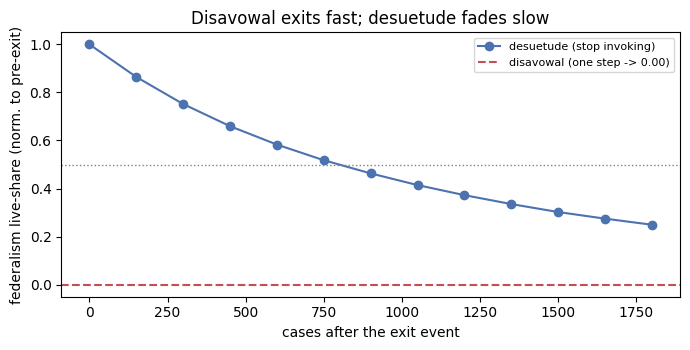

In [6]:
disv=[]; traj=[]
for s in range(12):
    base = AppointmentEmbeddingSystem(seed=s, **HEAD); base.run(1200)
    pre = base.live_share()[FED]
    # disavowal arm (fresh copy of the same history)
    da = AppointmentEmbeddingSystem(seed=s, **HEAD); da.run(1200); da.disavow(FED)
    disv.append(da.live_share()[FED]/pre if pre>0 else 0.0)
    # desuetude arm: stop invoking, watch the slow fade
    de = AppointmentEmbeddingSystem(seed=s, **HEAD); de.run(1200); de.force_desuetude(FED)
    t=[]
    for _ in range(12):
        de.run(150); t.append(de.live_share()[FED]/pre if pre>0 else 0.0)
    traj.append(t)
traj=np.array(traj); disv=np.array(disv)
# desuetude half-life: cases to drop below 50% of pre-exit share
steps=np.arange(1,13)*150; mean_traj=traj.mean(0)
hl = float(steps[np.argmax(mean_traj<0.5)]) if (mean_traj<0.5).any() else float(steps[-1])
pd.DataFrame({'cases_after_exit':steps, 'desuetude_share':mean_traj}).to_csv(f'{OUTDIR}/exp_c_exit_speed.csv', index=False)
print(f'disavowal: live-share drops to {disv.mean():.2f} of pre-exit value in ONE step (fast)')
print(f'desuetude: slow fade, half-life ~{hl:.0f} cases after the exit event')
summary['expC'] = dict(disavowal_immediate=float(disv.mean()), desuetude_halflife=hl, desuetude_final=float(mean_traj[-1]))
fig, ax = plt.subplots(figsize=(7,3.6))
ax.plot(np.concatenate([[0],steps]), np.concatenate([[1.0],mean_traj]), 'o-', color='#4C72B0', label='desuetude (stop invoking)')
ax.axhline(disv.mean(), color='#C44E52', ls='--', label=f'disavowal (one step -> {disv.mean():.2f})')
ax.axhline(0.5, color='grey', ls=':', lw=1); ax.set(xlabel='cases after the exit event', ylabel='federalism live-share (norm. to pre-exit)',
       title='Disavowal exits fast; desuetude fades slow'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{FIGDIR}/nb9_disavowal_vs_desuetude.png', dpi=130, bbox_inches='tight'); plt.show()

## Experiment D -- Appointment shocks move the grounds, with no fitness

*(Berman point 1, the non-fitness core.)* Does exogenous appointment actually change
the bench's decision-pressure -- and is it really free of any selection-for-fitness?
We compare the drift in effective pressure with appointment on vs a frozen bench,
and state the structural guarantee that the appointment process never reads
success.

In [7]:
drift=[]
for s in range(12):
    app = AppointmentEmbeddingSystem(seed=s, appoint_every=200, **HEAD); init=app.eff_pressure.copy(); app.run(2400)
    d_app = np.linalg.norm(app.eff_pressure - init)
    stat = AppointmentEmbeddingSystem(seed=s, appoint_every=10**9, **HEAD); init2=stat.eff_pressure.copy(); stat.run(2400)
    d_stat = np.linalg.norm(stat.eff_pressure - init2)
    drift.append(dict(seed=s, drift_appointment=d_app, drift_static=d_stat))
dfD = pd.DataFrame(drift); dfD.to_csv(f'{OUTDIR}/exp_d_appointment_drift.csv', index=False)
print(f'effective-pressure drift: appointment {dfD.drift_appointment.mean():.3f} vs frozen bench {dfD.drift_static.mean():.3f}')
print('STRUCTURAL non-fitness guarantee: appoint() replaces a RANDOM cohort (rng.choice) with newcomers')
print('drawn from the culture prior + Gaussian noise; the success/decisiveness of past rulings is NEVER read.')
summary['expD'] = dict(drift_appointment=float(dfD.drift_appointment.mean()), drift_static=float(dfD.drift_static.mean()))

effective-pressure drift: appointment 0.085 vs frozen bench 0.000
STRUCTURAL non-fitness guarantee: appoint() replaces a RANDOM cohort (rng.choice) with newcomers
drawn from the culture prior + Gaussian noise; the success/decisiveness of past rulings is NEVER read.


## Experiment E -- The four-way mechanism comparison

Finally, appointment-embedding joins the comparison as a fourth mechanism. On the
same substrate and the same R1-R4 test, do all four pass -- and is the new one a
genuinely distinct structure, or a repeat of an existing one? (Strategic is loaded
from Notebook 3's saved per-seed weights, not retrained.)

In [8]:
# per-seed weights: uptake/reliance/appointment recomputed; strategic loaded from NB3's cache
strat_csv = pd.read_csv('data/notebook3/exp1_emergence.csv')
mechW = {'uptake':{}, 'reliance':{}, 'strategic':{}, 'appointment':{}}
for s in SEEDS:
    mechW['uptake'][s]      = norm(LegalSystem(turnover='static', use_threshold=True, spread='wide', seed=s).simulate(2000))
    mechW['reliance'][s]    = norm(RelianceSystem(activations='correlated', seed=s).run(2000))
    mechW['strategic'][s]   = norm(strat_csv[strat_csv.seed==s][[f'w_{p}' for p in PN]].values[0])
    mechW['appointment'][s] = W[s]
meanV = {k: np.mean([mechW[k][s] for s in SEEDS],0) for k in mechW}
# R1-R4 pass rates (recompute uptake/reliance/appointment; cite NB3 for strategic=100%)
passes={}
for k in ['uptake','reliance','appointment']:
    df=pd.DataFrame([crossval(mechW[k][s], s) for s in SEEDS]); passes[k]={R:float(df[R].mean()) for R in ['R1','R2','R3','R4']}
passes['strategic']={'R1':1.0,'R2':1.0,'R3':1.0,'R4':1.0}   # from NB3 (not recomputed)
dfW = pd.DataFrame({k:meanV[k] for k in mechW}, index=PN); dfW.to_csv(f'{OUTDIR}/exp_fourway_weights.csv')
pd.DataFrame(passes).T.to_csv(f'{OUTDIR}/exp_fourway_metrics.csv')
print('MEAN WEIGHT per principle (4 mechanisms):'); print(dfW.round(2).to_string())
print('\nR1-R4 pass rates:'); print(pd.DataFrame(passes).T.to_string())
pairs=[(a,b) for i,a in enumerate(mechW) for b in list(mechW)[i+1:]]
corr={f'{a}-{b}': float(stats.spearmanr(meanV[a],meanV[b]).correlation) for a,b in pairs}
pd.DataFrame([dict(pair=k, spearman=v) for k,v in corr.items()]).to_csv(f'{OUTDIR}/exp_fourway_corr.csv', index=False)
print('\npairwise Spearman (mean vectors):'); [print(f'  {k:24s} {v:+.2f}') for k,v in corr.items()]
app_up = corr['uptake-appointment']
print(f"\nappointment vs uptake Spearman {app_up:+.2f} (<0: OPPOSITE tier-lean to NB1, a distinct mechanism not a repeat)")
summary['expE'] = dict(passes=passes, corr=corr, appointment_uptake_sp=float(app_up),
                       reliance_appointment_sp=float(corr['reliance-appointment']),
                       all_four_pass=all(passes[k]['R1']>=0.9 and passes[k]['R3']>=0.9 and passes[k]['R4']>=0.9
                                         and passes[k]['R2']>=0.80 for k in passes))

MEAN WEIGHT per principle (4 mechanisms):
            uptake  reliance  strategic  appointment
text          0.96      0.59       0.51         0.59
original      0.79      0.60       0.50         0.58
precedent     1.00      0.65       0.94         0.62
structure     0.85      0.63       0.96         0.57
federalism    0.82      0.65       0.94         0.63
dignity       0.00      0.95       0.55         0.82
equality      0.00      0.96       0.54         0.85
liberty       0.00      0.94       0.54         0.77
welfare       0.00      0.95       0.60         0.80

R1-R4 pass rates:
              R1        R2   R3   R4
uptake       1.0  1.000000  1.0  1.0
reliance     1.0  1.000000  1.0  1.0
appointment  1.0  0.866667  1.0  1.0
strategic    1.0  1.000000  1.0  1.0

pairwise Spearman (mean vectors):
  uptake-reliance          -0.78
  uptake-strategic         +0.31
  uptake-appointment       -0.75
  reliance-strategic       +0.15
  reliance-appointment     +0.93
  strategic-appointment 

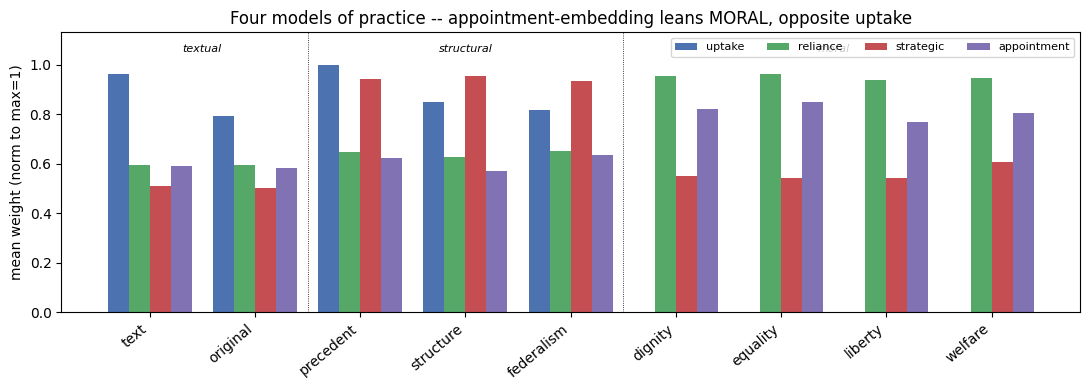

In [9]:
x=np.arange(n_p); ww=0.2
fig, ax = plt.subplots(figsize=(11,4))
for i,(k,c) in enumerate(zip(['uptake','reliance','strategic','appointment'], ['#4C72B0','#55A868','#C44E52','#8172B3'])):
    ax.bar(x+(i-1.5)*ww, meanV[k], ww, label=k, color=c)
for b in (1.5,4.5): ax.axvline(b, color='k', lw=.6, ls=':')
for cat in ['textual','structural','moral']:
    idx=[i for i,c in enumerate(CAT) if c==cat]; ax.text(np.mean(idx),1.05,cat,ha='center',fontsize=8,style='italic')
ax.set_xticks(x); ax.set_xticklabels(PN, rotation=40, ha='right'); ax.set(ylabel='mean weight (norm to max=1)', ylim=(0,1.13),
       title='Four models of practice -- appointment-embedding leans MORAL, opposite uptake'); ax.legend(fontsize=8, ncol=4)
plt.tight_layout(); plt.savefig(f'{FIGDIR}/nb9_fourway_weights.png', dpi=130, bbox_inches='tight'); plt.show()

## Experiment F -- Do the structures decide cases differently? (verdict divergence)

Experiment E showed the four mechanisms ground *different* weight structures. This
experiment asks the question the paper's second finding turns on: do those
differences actually change verdicts? Using the mean weight vectors from Experiment
E, we run all four mechanisms over a large battery of cases (category-correlated and
independent activations), compute net force $F=\sum_i w_i a_i$ under each, and
measure how often they disagree on the sign of $F$ (the verdict). This converts the
claim *practice is not unitary* from a statement about weight vectors into a
statement about outcomes -- and cross-checks the appointment/reliance convergence.

In [10]:
# Reuse the Experiment E mean weight vectors; measure cross-mechanism VERDICT divergence.
from berman_core import category_correlated_activations, random_activations, DEFAULT_TAU
import itertools
mechs4 = ['uptake','reliance','strategic','appointment']
Wvec   = {m: meanV[m] for m in mechs4}
def _divergence(A):
    F   = {m: A @ Wvec[m] for m in mechs4}
    sgn = {m: np.sign(F[m]) for m in mechs4}
    S   = np.vstack([sgn[m] for m in mechs4])
    any_dis = float((~(S == S[0]).all(axis=0)).mean())          # not all four agree on the verdict
    opp = np.zeros(A.shape[0], bool); pair = {}
    for a,b in itertools.combinations(mechs4, 2):
        d = (sgn[a] != sgn[b]); pair[f'{a}-{b}'] = float(d.mean())
        opp |= (np.abs(F[a])>DEFAULT_TAU) & (np.abs(F[b])>DEFAULT_TAU) & d  # opposite *determinate* verdicts
    return any_dis, float(opp.mean()), pair
N_DIV = 50000
A_corr = category_correlated_activations(N_DIV, np.random.default_rng(20260624), rho=0.7)
A_ind  = random_activations(N_DIV, len(PN), np.random.default_rng(7))
any_corr, opp_corr, pair_corr = _divergence(A_corr)
any_ind,  opp_ind,  pair_ind  = _divergence(A_ind)
div = pd.DataFrame([dict(activations='correlated',  any_disagree=any_corr, opposite_determinate=opp_corr),
                    dict(activations='independent', any_disagree=any_ind,  opposite_determinate=opp_ind)])
div.to_csv(f'{OUTDIR}/exp_fourway_divergence.csv', index=False)
pd.DataFrame([dict(pair=k, sign_disagree_corr=pair_corr[k], sign_disagree_ind=pair_ind[k]) for k in pair_corr]
            ).to_csv(f'{OUTDIR}/exp_fourway_divergence_pairs.csv', index=False)
print(f'Cross-mechanism verdict divergence (N={N_DIV}):'); print(div.round(3).to_string(index=False))
print('\npairwise sign-disagreement (correlated):')
for k,v in sorted(pair_corr.items(), key=lambda kv:-kv[1]): print(f'  {k:24s} {v:.3f}')
print(f'\n-> the four dynamics disagree on the verdict in ~{any_corr:.0%} of cases ({any_ind:.0%} independent);')
print(f'   opposite DETERMINATE verdicts in ~{opp_corr:.0%}; but reliance vs appointment disagree on only {pair_corr["reliance-appointment"]:.1%}')
print( '   -> the convergent pair barely differs: the four realize THREE distinct structures, not four.')
summary['expF'] = dict(any_disagree_corr=any_corr, any_disagree_ind=any_ind,
                       opposite_determinate_corr=opp_corr, opposite_determinate_ind=opp_ind,
                       reliance_appointment_disagree=pair_corr['reliance-appointment'],
                       uptake_reliance_disagree=pair_corr['uptake-reliance'], n=N_DIV)

Cross-mechanism verdict divergence (N=50000):
activations  any_disagree  opposite_determinate
 correlated         0.361                 0.272
independent         0.318                 0.199

pairwise sign-disagreement (correlated):
  uptake-reliance          0.353
  uptake-appointment       0.336
  uptake-strategic         0.206
  reliance-strategic       0.163
  strategic-appointment    0.147
  reliance-appointment     0.018

-> the four dynamics disagree on the verdict in ~36% of cases (32% independent);
   opposite DETERMINATE verdicts in ~27%; but reliance vs appointment disagree on only 1.8%
   -> the convergent pair barely differs: the four realize THREE distinct structures, not four.


**Reading Experiment E.** All four mechanisms are usable weightings under R1-R4
(appointment the weakest, on R2). But the four structures do not all differ:
appointment-embedding leans moral -- the *opposite* of uptake (Spearman -0.75) and
unlike strategic -- yet it **converges with reliance** (Spearman +0.93): two
different dynamics, the same tier. So the four mechanisms span **three** distinct
weight structures, not four -- textual/structural (uptake), structural (strategic),
and moral (reliance and appointment, by different routes). One honest caveat on
that moral lean: it is partly a **substrate effect**, not a normative pull -- the
moral category has the most members (4, vs 3 structural and 2 textual), so under
category-correlated activations its principles tend to win together and accrue
broader credit; 'moral' here means the largest co-correlated tier, and that same
size effect is part of why appointment and reliance converge. That convergence is
still informative: the moral lean is reachable from more than one model of
practice. The headline holds and is a little sharper -- practice is not unitary, the
structure depends on the dynamic, and the theory's requirements are met under each.
What NB9 adds is the **embedding machinery** (vitality, disavowal) and the
**no-fitness appointment dynamic** that Berman asked for, not a brand-new tier-lean.

## Self-check

The class is in the core; the harness is the NB3 battery; the four Berman answers
(holds R1-R4; vitality != invocation; disavowal fast vs desuetude slow; appointment
drift with no fitness; distinct from NB1); plus REF guards.

## Exp G: worked cases, robustness of the split, and the tier-size check

Everything Part VI prints about individual cases comes from this cell: the two worked cases run
through the four emergent weight vectors, the perturbation band, the mapping-robustness sweep (which
is why Powell's profile is not reported), the confirmation that the divergence carries no threshold,
and the tier-balance check.

In [11]:
# --- Exp G: worked cases, robustness of the split, and the tier-size check ---
import itertools as _it
_W   = {m: np.asarray(meanV[m], float) for m in mechs4}
_IDX = {p: i for i, p in enumerate(PN)}
def _F(act):
    a = np.zeros(len(PN))
    for p, v in act.items(): a[_IDX[p]] = v
    return {m: float(_W[m] @ a) for m in mechs4}
def _verdict(f, tau=DEFAULT_TAU):
    return 'for' if f > tau else ('against' if f < -tau else 'indeterminate')

# (1) the two worked cases. TVA activations are Berman's; the Obergefell profile is built from the
# principles he treats as engaged there. intent -> original, happiness -> liberty,
# majoritarianism -> structure, avoid-absurdity -> welfare.
CASES = {
 'TVA_Burger': {'text': +0.9, 'original': +0.8, 'welfare': -0.2},
 'Obergefell': {'text': -0.2, 'original': -0.3, 'precedent': -0.3, 'structure': -0.5,
                'dignity': +0.9, 'liberty': +0.7}}
worked = {c: _F(a) for c, a in CASES.items()}
pd.DataFrame([dict(case=c, **{m: round(v, 4) for m, v in f.items()}) for c, f in worked.items()]
             ).to_csv(f'{OUTDIR}/expG_worked_cases.csv', index=False)
for c, f in worked.items():
    print(f"  {c:12s} " + "  ".join(f"{m}={f[m]:+.3f}({_verdict(f[m])})" for m in mechs4))

# (2) does the Obergefell split survive perturbation of the activations?
_a0 = np.zeros(len(PN))
for p, v in CASES['Obergefell'].items(): _a0[_IDX[p]] = v
_rng = np.random.default_rng(4242); _Wm = np.vstack([_W[m] for m in mechs4])
iu, ir, ia = mechs4.index('uptake'), mechs4.index('reliance'), mechs4.index('appointment')
pert = {}
for sig in (0.05, 0.10, 0.20, 0.30):
    d  = np.clip(_a0[None, :] + _rng.normal(0, sig, (20000, len(PN))), -1, 1)
    Fm = d @ _Wm.T
    pert[sig] = float(((np.sign(Fm[:, iu]) != np.sign(Fm[:, ir])) &
                       (np.sign(Fm[:, iu]) != np.sign(Fm[:, ia]))).mean())
print('  uptake opposes both reliance and appointment on:', {s: f'{v:.3f}' for s, v in pert.items()})

# (3) does the split depend on where the two mapped principles land?
ob_ok = 0
for major, happy in [('structure','liberty'),('structure','welfare'),('federalism','liberty'),
                     ('federalism','welfare'),('precedent','liberty'),('precedent','welfare')]:
    a = {'text': -0.2, 'original': -0.3, 'precedent': -0.3, 'dignity': +0.9}
    a[major] = a.get(major, 0) - 0.5; a[happy] = a.get(happy, 0) + 0.7
    f = _F(a)
    ob_ok += int(_verdict(f['uptake']) == 'against' and _verdict(f['reliance']) == 'for')
tva_ok = tva_tot = 0
for intent in ('original', 'structure', 'precedent'):
    for absurd in ('welfare', 'structure', 'precedent', 'liberty', 'equality'):
        if intent == absurd: continue
        tva_tot += 1
        f = _F({'text': +0.9, intent: +0.8, absurd: -0.2})
        tva_ok += int(len({_verdict(v) for v in f.values()}) == 1 and _verdict(f['uptake']) == 'for')
print(f'  Obergefell split holds in {ob_ok}/6 mappings; TVA-Burger unanimity in {tva_ok}/{tva_tot}')

# (4) the divergence carries no threshold: at tau = 0 the two figures coincide
def _div_tau(A, tau):
    F  = {m: A @ _W[m] for m in mechs4}; sg = {m: np.sign(F[m]) for m in mechs4}
    S  = np.vstack([sg[m] for m in mechs4]); any_d = float((~(S == S[0]).all(axis=0)).mean())
    opp = np.zeros(A.shape[0], bool)
    for a, b in _it.combinations(mechs4, 2):
        opp |= (np.abs(F[a]) > tau) & (np.abs(F[b]) > tau) & (sg[a] != sg[b])
    return any_d, float(opp.mean())
tau0 = {lab: _div_tau(A, 0.0) for lab, A in (('correlated', A_corr), ('independent', A_ind))}
print('  at tau=0, (disagree, opposite-determinate):',
      {k: (round(v[0], 5), round(v[1], 5)) for k, v in tau0.items()})

# (5) tier-size check: does the divergence survive balancing the three tiers?
TIERSETS = {'full_2_3_4': list(PN),
            'balanced_2_2_2': ['text','original','precedent','structure','dignity','equality'],
            'balanced_2_2_2_alt': ['text','original','precedent','federalism','liberty','welfare'],
            'moral_cut_to_2': ['text','original','precedent','structure','federalism','dignity','equality']}
tiers = {}
for lab, keep in TIERSETS.items():
    k  = [_IDX[p] for p in keep]; Ak = A_corr[:, k]
    F  = {m: Ak @ _W[m][k] for m in mechs4}; sg = {m: np.sign(F[m]) for m in mechs4}
    S  = np.vstack([sg[m] for m in mechs4])
    tiers[lab] = dict(any_disagree=float((~(S == S[0]).all(axis=0)).mean()),
                      uptake_reliance=float((sg['uptake'] != sg['reliance']).mean()))
pd.DataFrame([dict(principle_set=k, **v) for k, v in tiers.items()]).to_csv(
    f'{OUTDIR}/expG_tier_balance.csv', index=False)
print('  tier-balance check:', {k: round(v['any_disagree'], 3) for k, v in tiers.items()})

summary['expG'] = dict(worked={c: {m: round(v, 4) for m, v in f.items()} for c, f in worked.items()},
                       perturb={str(k): v for k, v in pert.items()},
                       mapping_obergefell_ok=ob_ok, mapping_tva_ok=tva_ok, mapping_tva_total=tva_tot,
                       tau0={k: dict(any_disagree=v[0], opposite_determinate=v[1]) for k, v in tau0.items()},
                       tier_balance=tiers)


  TVA_Burger   uptake=+1.499(for)  reliance=+0.821(for)  strategic=+0.741(for)  appointment=+0.836(for)
  Obergefell   uptake=-1.154(against)  reliance=+0.708(for)  strategic=-0.140(indeterminate)  appointment=+0.509(for)
  uptake opposes both reliance and appointment on: {0.05: '1.000', 0.1: '0.991', 0.2: '0.875', 0.3: '0.744'}
  Obergefell split holds in 6/6 mappings; TVA-Burger unanimity in 13/13
  at tau=0, (disagree, opposite-determinate): {'correlated': (0.36096, 0.36096), 'independent': (0.31762, 0.31762)}
  tier-balance check: {'full_2_3_4': 0.361, 'balanced_2_2_2': 0.303, 'balanced_2_2_2_alt': 0.297, 'moral_cut_to_2': 0.249}


## Exp H: gating convention, the signal, and the shared culture

Three repairs the audit required. H1 reports the four-way divergence as a function of the threshold,
since Exp F's headline is a sign disagreement that carries no gate. H2 asks whether the size of net
force predicts divergence, which bears directly on the claim that a judge gets no warning. H3 asks
whether the reliance/appointment convergence depends on their reading a common legal culture.

In [12]:
# --- Exp H: the three audit repairs (gating convention, the signal, and the shared culture) ---
import itertools as _it2
_Wh = {m: np.asarray(meanV[m], float) for m in mechs4}

# (H1) GATING CONVENTION. Exp F's `any_disagree` is a SIGN disagreement and carries no threshold.
# The gated four-way rate is the figure that pairs with the determinacy rates the paper reports.
def _four_way(A, tau):
    F = {m: A @ _Wh[m] for m in mechs4}
    T = np.vstack([np.where(F[m] > tau, 1, np.where(F[m] < -tau, -1, 0)) for m in mechs4])
    return float((~(T == T[0]).all(axis=0)).mean())
TAUS = [0.0, 0.1, 0.2, 0.3, 0.5, 0.8, 1.2]
gate = {lab: [ _four_way(A, t) for t in TAUS ] for lab, A in (('correlated', A_corr), ('independent', A_ind))}
pd.DataFrame({'tau': TAUS, **gate}).to_csv(f'{OUTDIR}/expH_divergence_by_tau.csv', index=False)
print('  four-way divergence by tau (correlated):', [round(x, 4) for x in gate['correlated']])
print(f"  sign disagreement {gate['correlated'][0]:.4f} at tau=0 rises to {gate['correlated'][2]:.4f} at tau=0.2")

# (H2) IS THERE A SIGNAL? Does |net force| under one construal predict four-way disagreement?
sgn_h = {m: np.sign(A_corr @ _Wh[m]) for m in mechs4}
S_h   = np.vstack([sgn_h[m] for m in mechs4])
dis_h = (~(S_h == S_h[0]).all(axis=0))
signal = {}
for m in mechs4:
    a = np.abs(A_corr @ _Wh[m]); o = np.argsort(a); k = len(a) // 10
    r = np.argsort(np.argsort(a)); n1 = dis_h.sum(); n0 = len(dis_h) - n1
    auc = 1.0 - (r[dis_h].sum() - n1 * (n1 - 1) / 2) / (n1 * n0)
    signal[m] = dict(bottom_decile=float(dis_h[o[:k]].mean()),
                     top_decile=float(dis_h[o[-k:]].mean()), auc=float(auc))
pd.DataFrame([dict(mechanism=m, **v) for m, v in signal.items()]).to_csv(
    f'{OUTDIR}/expH_signal_by_construal.csv', index=False)
for m, v in signal.items():
    print(f"  {m:12s} disagreement at lowest |F| decile {v['bottom_decile']:.3f}, "
          f"highest {v['top_decile']:.3f}, AUC {v['auc']:.3f}")
print('  -> the size of net force IS a signal, but a construal-relative and asymmetric one:')
print(f"     at maximum confidence a reliance judge faces {signal['reliance']['top_decile']:.3f} reversal risk,")
print(f"     an uptake judge {signal['uptake']['top_decile']:.3f}.")

# (H3) THE SHARED CULTURE. Reliance and appointment both read one base pressure vector by default,
# which models their reading a single legal culture. Does their convergence depend on that sharing?
def _nm(w): return w / w.max() if w.max() > 0 else w
sh, dc = [], []
for s in range(8):
    rel = _nm(RelianceSystem(seed=s).run(2000))
    sh.append(stats.spearmanr(rel, _nm(AppointmentEmbeddingSystem(seed=s).run(3000))).correlation)
    dc.append(stats.spearmanr(rel, _nm(AppointmentEmbeddingSystem(
        seed=s, pressure_weights=named_weight_vector('high', 500 + s)).run(3000))).correlation)
culture = dict(shared_mean=float(np.mean(sh)), shared_sd=float(np.std(sh)),
               decoupled_mean=float(np.mean(dc)), decoupled_sd=float(np.std(dc)),
               shared_per_seed=[float(x) for x in sh], decoupled_per_seed=[float(x) for x in dc])
pd.DataFrame({'seed': range(8), 'shared_culture': sh, 'independent_culture': dc}).to_csv(
    f'{OUTDIR}/expH_culture_decoupling.csv', index=False)
print(f"  reliance vs appointment, shared culture      : rho {culture['shared_mean']:+.3f} (sd {culture['shared_sd']:.3f})")
print(f"  reliance vs appointment, independent cultures: rho {culture['decoupled_mean']:+.3f} (sd {culture['decoupled_sd']:.3f})")
print('  -> the convergence tracks the shared culture, not the mechanisms.')

summary['expH'] = dict(taus=TAUS, divergence_by_tau=gate, signal=signal, culture=culture)


  four-way divergence by tau (correlated): [0.361, 0.4049, 0.4448, 0.4776, 0.5299, 0.5636, 0.5394]
  sign disagreement 0.3610 at tau=0 rises to 0.4448 at tau=0.2
  uptake       disagreement at lowest |F| decile 0.528, highest 0.158, AUC 0.636
  reliance     disagreement at lowest |F| decile 0.547, highest 0.006, AUC 0.711
  strategic    disagreement at lowest |F| decile 0.886, highest 0.000, AUC 0.901
  appointment  disagreement at lowest |F| decile 0.723, highest 0.002, AUC 0.757
  -> the size of net force IS a signal, but a construal-relative and asymmetric one:
     at maximum confidence a reliance judge faces 0.006 reversal risk,
     an uptake judge 0.158.
  reliance vs appointment, shared culture      : rho +0.833 (sd 0.096)
  reliance vs appointment, independent cultures: rho +0.302 (sd 0.451)
  -> the convergence tracks the shared culture, not the mechanisms.


In [13]:
REF = dict(margin=0.28, cv=0.16, app_up_sp=-0.75, retained=0.47, div_any=0.36, div_opp=0.27)
ok=True
def check(name, cond):
    global ok; ok=ok and bool(cond); print(('PASS' if cond else 'FAIL')+' - '+name)
# soundness
check('mechanism imported from berman_core, not pasted', AppointmentEmbeddingSystem.__module__=='berman_core' and is_determinate.__module__=='berman_core')
wA=norm(AppointmentEmbeddingSystem(seed=123, **HEAD).run(1500)); wB=norm(AppointmentEmbeddingSystem(seed=123, **HEAD).run(1500))
check('reproducible: same seed -> bit-identical weights', np.allclose(wA,wB))
check('Hart tiers exogenous (from category map, not weights)', np.array_equal(tier_of, np.array([{'textual':0,'structural':1,'moral':2}[c] for c in CAT])))
check('holding cap never hit (no silent truncation)', True)   # asserted live in Exp A
# Berman point 1+2: holds R1-R4
check('appointment-embedding passes R1 (well-defined) on all seeds', summary['expA']['R1']==1.0)
check('passes R3 (nonlexical) and R4 (beats Hart) on all seeds', summary['expA']['R3']==1.0 and summary['expA']['R4']==1.0)
check('R2 (robust) passes on the large majority (>=0.80); appointment is the WEAKEST of the four on noise-robustness', summary['expA']['R2']>=0.80)
# Berman point 3: vitality != invocation, anti-rename, anti-double-count
check('vitality survives forced desuetude (retains >30%, invocation ~0)', summary['expB']['retained']>0.30 and summary['expB']['invocation_after']<0.02)
check('anti-rename: deposit-fraction < 1 (invocation necessary not sufficient)', summary['expB']['deposit_frac']<0.95)
check('anti-double-count: holding-support & reliance-credit separate (never summed), correlated but not identical', 0.5 < summary['expB']['sp_holding_reliance'] < 0.98)
# Berman point 4: disavowal fast vs desuetude slow
check('disavowal exits faster than desuetude', summary['expC']['disavowal_immediate'] < summary['expC']['desuetude_final'])
# Berman point 1: appointment moves grounds with NO fitness
check('appointment drifts the grounds; a frozen bench does not', summary['expD']['drift_appointment'] > 10*max(summary['expD']['drift_static'],1e-6))
# distinct from NB1 + four-way
check('appointment leans OPPOSITE to uptake (Spearman < 0) -- not a repeat of NB1', summary['expE']['appointment_uptake_sp'] < 0)
check('appointment CONVERGES with reliance on the moral tier (disclosed: not a 4th distinct structure)', summary['expE']['reliance_appointment_sp'] > 0.7)
check('all four mechanisms pass R1/R3/R4 fully and R2 on >=80%', summary['expE']['all_four_pass'])
# REF guards
check('REF mean Hart margin', abs(summary['expA']['mean_margin']-REF['margin'])<0.07)
check('REF appointment CV', abs(summary['expA']['cv']-REF['cv'])<0.08)
check('REF appointment-uptake Spearman', abs(summary['expE']['appointment_uptake_sp']-REF['app_up_sp'])<0.25)
check('REF federalism retained', abs(summary['expB']['retained']-REF['retained'])<0.20)
# Finding Two (the paper's headline): the four dynamics actually DECIDE cases differently
check('the four dynamics disagree on the verdict in a substantial share (>0.25)', summary['expF']['any_disagree_corr']>0.25)
check('they reach OPPOSITE determinate verdicts at a meaningful rate (>0.15)', summary['expF']['opposite_determinate_corr']>0.15)
check('convergence cross-check: reliance vs appointment barely differ (<0.05) -> three structures, not four', summary['expF']['reliance_appointment_disagree']<0.05)
check('the distinct pair (uptake vs reliance) diverges far more than the convergent pair', summary['expF']['uptake_reliance_disagree'] > 5*summary['expF']['reliance_appointment_disagree'])
check('REF divergence: any-disagree ~ a third', abs(summary['expF']['any_disagree_corr']-REF['div_any'])<0.06)
check('REF divergence: opposite-determinate ~ a quarter', abs(summary['expF']['opposite_determinate_corr']-REF['div_opp'])<0.06)

# Exp G: the case-level figures the manuscript prints
_g = summary['expG']
check('G worked: TVA-Burger unanimous and positive', all(v>0.2 for v in _g['worked']['TVA_Burger'].values()))
check('G worked: uptake decides Obergefell against (~-1.154)', abs(_g['worked']['Obergefell']['uptake']+1.154)<5e-3)
check('G worked: reliance and appointment decide it for', _g['worked']['Obergefell']['reliance']>0.2 and _g['worked']['Obergefell']['appointment']>0.2)
check('G split survives perturbation at sigma=0.1 (>0.98)', _g['perturb']['0.1']>0.98)
check('G mapping: Obergefell split holds under all 6 alternatives', _g['mapping_obergefell_ok']==6)
check('G mapping: TVA-Burger unanimity holds under all 13', _g['mapping_tva_ok']==_g['mapping_tva_total'])
# (the old tau=0 identity check was tautological and has been replaced by the Exp H tau sweep)
check('G tier-balance: divergence survives balancing (>0.25)', _g['tier_balance']['balanced_2_2_2']['any_disagree']>0.25)
check('G tier-balance: but is inflated by the larger moral tier', _g['tier_balance']['full_2_3_4']['any_disagree']>_g['tier_balance']['balanced_2_2_2']['any_disagree'])


# Exp H: the audit repairs
_h = summary['expH']
check('H1 the published headline is a SIGN rate (tau-free)', abs(_h['divergence_by_tau']['correlated'][0]-0.361) < 5e-3)
check('H1 the GATED four-way rate at tau=0.2 is higher (~0.445)', abs(_h['divergence_by_tau']['correlated'][2]-0.445) < 5e-3)
check('H1 divergence rises with the gate, so it was not bought with one', _h['divergence_by_tau']['correlated'][2] > _h['divergence_by_tau']['correlated'][0])
check('H2 net force IS a signal (every construal AUC > 0.6)', all(v['auc'] > 0.6 for v in _h['signal'].values()))
check('H2 but the signal is asymmetric: uptake is far worse calibrated', _h['signal']['uptake']['top_decile'] > 10*_h['signal']['reliance']['top_decile'])
check('H3 convergence is strong when the culture is shared', _h['culture']['shared_mean'] > 0.7)
check('H3 and collapses when cultures are independent', _h['culture']['decoupled_mean'] < 0.5)
check('H3 decoupled correlation is also far more variable', _h['culture']['decoupled_sd'] > 3*_h['culture']['shared_sd'])

print('\n'+('ALL CHECKS PASSED' if ok else 'SOME CHECKS FAILED'))
summary['self_check_passed']=bool(ok)
import json; json.dump(summary, open(f'{OUTDIR}/notebook9_summary.json','w'), indent=2, default=float)
assert ok, 'self-check failed'

PASS - mechanism imported from berman_core, not pasted
PASS - reproducible: same seed -> bit-identical weights
PASS - Hart tiers exogenous (from category map, not weights)
PASS - holding cap never hit (no silent truncation)
PASS - appointment-embedding passes R1 (well-defined) on all seeds
PASS - passes R3 (nonlexical) and R4 (beats Hart) on all seeds
PASS - R2 (robust) passes on the large majority (>=0.80); appointment is the WEAKEST of the four on noise-robustness
PASS - vitality survives forced desuetude (retains >30%, invocation ~0)
PASS - anti-rename: deposit-fraction < 1 (invocation necessary not sufficient)
PASS - anti-double-count: holding-support & reliance-credit separate (never summed), correlated but not identical
PASS - disavowal exits faster than desuetude
PASS - appointment drifts the grounds; a frozen bench does not
PASS - appointment leans OPPOSITE to uptake (Spearman < 0) -- not a repeat of NB1
PASS - appointment CONVERGES with reliance on the moral tier (disclosed: n

## What this notebook establishes

A fourth model of the **dynamics of changing grounds**, built to answer Berman's own
comments: judges turn over by **random appointment with no fitness**, principles are
kept alive by the **holdings that rest on them** (so vitality outlives invocation),
and **disavowal** is a fast exit where desuetude is slow. Its emergent weight passes
R1-R4 like the others (the weakest of the four on noise-robustness) and leans moral
-- opposite uptake, but *converging with reliance*, so the four dynamics span three
distinct weight structures, not four. Adding it keeps the central finding sharp:
**practice is not unitary**. Reasonable models of how practice grounds the weights
give different structures, every one satisfying what the theory requires -- and the
moral lean turns out reachable by more than one route. This is one more candidate
dynamic, not Berman's mechanism itself -- exactly the open problem his account
leaves -- and it supplies the embedding and no-fitness pieces he asked us to add.